## Read the data

In [1]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"
EXPERIMENT = 'core_identification'

# 1. Read data (Now it is the same data)

In [2]:
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
# DATA_PATH_BASE = 'D:/Google Drive/Work/ITMO/data' #windows
# DATA_PATH_BASE = '/home/denklewer/Data' #ubuntu

DATA_PATH = f'{DATA_PATH_BASE}/{EXPERIMENT}/per_length_per_kfold_split/' # work laptop
APPROACH = "DECOY_PATHS"

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
# per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
# per_allele_per_kfold_per_length_non_binders_test| = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
# ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#           ]
ALLELES = [
   # 'HLA-A*01:01',
    #'HLA-A*03:01',
    # 'HLA-A*02:01б'
   #'HLA-DRB1*01:01',
    # 'HLA-DQA1*05:01/DQB1*02:01',
    'HLA-DPA1*02:02/DPB1*05:01',
          ]
selected_alleles = ALLELES
ALLELES

['HLA-DPA1*02:02/DPB1*05:01']

In [4]:
per_allele_per_kfold_per_length_binders_train.keys()

dict_keys(['HLA-DPA1*02:02/DPB1*05:01', 'HLA-DQA1*05:01/DQB1*02:01'])

## 2.0 Merge alleles together

In [5]:
# combination_size = len(ALLELES)
#ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'])
# ALLELES = sorted([ 'HLA-A*03:01'])
#ALLELES = sorted(['HLA-DRB1*01:01',
                  # 'HLA-DPA1*01:03/DPB1*04:01'
               #   ])
# ALLELES = sorted(['HLA-DPA1*01:03-DPB1*04:01'])
#
# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])
#

combination_size = 1
TOTAL_SPLITS = 1
TARGET_LENGTHS= [11, 12, 13, 14, 15, 16, 17, 18]
# TARGET_LENGTHS= [8, 9, 10, 11, 12]
RUNS = 20
USE_WEIGHTS = True

# SELECTED_RUN = 0
# SELECTED_RUN = {0,1,2,3,4,5, 6, 7, 8, 9}
SELECTED_RUN = {0,1}

# SELECTED_RUN = {0}
#
SELECTED_SPLIT = 0
models_to_read = ['v']

In [6]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-DPA1*02:02/DPB1*05:01
Length 9: HLA-DPA1*02:02/DPB1*05:01 - 12 
Length 10: HLA-DPA1*02:02/DPB1*05:01 - 53 
Length 11: HLA-DPA1*02:02/DPB1*05:01 - 204 
Length 12: HLA-DPA1*02:02/DPB1*05:01 - 420 
Length 13: HLA-DPA1*02:02/DPB1*05:01 - 790 
Length 14: HLA-DPA1*02:02/DPB1*05:01 - 1241 
Length 15: HLA-DPA1*02:02/DPB1*05:01 - 1231 
Length 16: HLA-DPA1*02:02/DPB1*05:01 - 927 
Length 17: HLA-DPA1*02:02/DPB1*05:01 - 628 
Length 18: HLA-DPA1*02:02/DPB1*05:01 - 403 
Length 19: HLA-DPA1*02:02/DPB1*05:01 - 232 
Length 20: HLA-DPA1*02:02/DPB1*05:01 - 121 
Length 21: HLA-DPA1*02:02/DPB1*05:01 - 72 
Length 22: HLA-DPA1*02:02/DPB1*05:01 - 36 
Length 23: HLA-DPA1*02:02/DPB1*05:01 - 25 
Length 24: HLA-DPA1*02:02/DPB1*05:01 - 9 
Length 25: HLA-DPA1*02:02/DPB1*05:01 - 10 
Length 26: HLA-DPA1*02:02/DPB1*05:01 - 6 


# Read models

In [7]:
MODELS_DESCRIPTIONS = {

               "viterbi_models_multiple_motifs_21_12_18_com2": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22],
        "core_end_state": [23,24],
        "need_to_delete": [111]

    },
    
           "viterbi_models_multiple_motifs_21_12_18_com3": {
        "path": "experiment_results/core_identification/",
        "states": 21,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [21,22, 23],
        "core_end_state": [24,25, 26],
        "need_to_delete": [111]

    },
    
               "viterbi_models_multiple_motifs_14_12_18_com3": {
        "path": "experiment_results/core_identification/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18, 19],
        "need_to_delete": [111]

    },
    
           "viterbi_models_multiple_motifs_14_12_18_com3": {
        "path": "experiment_results/core_identification/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18, 19],
        "need_to_delete": [111]

    },
               "core_identification_pseudocount_anchor": {
        "path": "experiment_results/core_identification_pseudocount_anchor/",
        "states": 14,
        "params_string": "30-min_iters",
        "combination_size": 1,
        "alleles": [
                 'HLA-DQA1*05:01/DQB1*02:01', 
                'HLA-DPA1*02:02/DPB1*05:01'

                    # 'HLA-A*02:01'
                    ],
        "target_lengths": [12, 13, 14, 15, 16, 17, 18],
        "core_start_state": [14,15, 16],
        "core_end_state": [17,18, 19],
        "need_to_delete": [111]

    },






    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

In [8]:
MODELS_DESCRIPTIONS.keys()

dict_keys(['viterbi_models_multiple_motifs_21_12_18_com2', 'viterbi_models_multiple_motifs_21_12_18_com3', 'viterbi_models_multiple_motifs_14_12_18_com3', 'core_identification_pseudocount_anchor'])

In [9]:
selected_models = [
                 #'single_allele_imbalanced',
                 #'multiple_allele_imbalanced',
                    # 'single_allele_balanced',
                   # 'multiple_allele_balanced',
    # "single_allele_balanced_class2",
    #     "single_allele_with_cycle_base_model",
    # "single_allele_with_cycle_base_model"
     "core_identification_pseudocount_anchor"

    # 'multiple_allele_balanced_longer_training'
]


In [10]:
from hmm_logic_methods import load_model

In [11]:
import itertools

name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
name_to_target_lengths = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type, target_lengths ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type
    name_to_target_lengths[model_name] = target_lengths

for model in selected_models:
    model_description = MODELS_DESCRIPTIONS[model]
    combination_size = model_description['combination_size']
    model_alleles = model_description['alleles']
    MODELS_PATH = model_description['path']
    params_string = model_description['params_string']
    states = model_description['states']
    TARGET_LENGTHS = model_description['target_lengths']
    target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
    MIXED_ALLELES = list()

    model_alleles = set(model_alleles).intersection(set(OLD_ALLELES))
    for combination in itertools.combinations(sorted(model_alleles), combination_size):
        allele_name = "+".join(combination)
        # allele_name = f"{allele_name1}+{allele_name2}"
        MIXED_ALLELES.append(allele_name)

    for allele_name in MIXED_ALLELES:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_').replace("/", "_")
        for run_num_b in range(RUNS):
            for split_num_b in range(TOTAL_SPLITS):
                #bw
                if 'bw' in models_to_read:
                    bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    print(bw_model_name)
                    populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'bwv' in models_to_read:
                    #bwv
                    bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-{params_string}_model-{target_allele_name}-{split_num_b}_plus_viterbi"
                    populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})", TARGET_LENGTHS)
                if 'v' in models_to_read:
                    #v
                    v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-{params_string}_model-{target_allele_name}-{split_num_b}"
                    populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})", TARGET_LENGTHS)



for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

## Mark important states in model(will be used for core call)

In [12]:
import logomaker
from collections import defaultdict
def probs_to_info_matrix(distribution):
    amino_acids = list(distribution.parameters[0].keys())
    dummy_df = pd.DataFrame(columns = sorted(amino_acids), index=[0],  dtype=float)
    for i, (acid, prob) in enumerate(distribution.parameters[0].items()):
        dummy_df.loc[0, acid] = prob
    dummy_df.index.name = "pos"
    info_matrix = logomaker.transform_matrix(dummy_df, from_type='probability', to_type='information')
    return info_matrix

per_model_total_df = dict()

for model_key, model in per_name_binding_model.items():
    per_state_information = dict()
    per_state_distribution = dict()
    per_level_information = defaultdict(float)

    for state in model.states:
        if state not in [model.start, model.end]:
            info_matrix = probs_to_info_matrix(state.distribution)
            per_state_distribution[state.name] = state.distribution.parameters[0]
            per_state_information[state.name] = sum(info_matrix.loc[0])
            # per_level_information[name_to_level[state.name]] += per_state_information[state.name]
    info_df = pd.DataFrame(per_state_information.items(), columns=["state", "info"])
    distr_df = pd.DataFrame(per_state_distribution.values())
    total_df = pd.concat([info_df, distr_df], axis=1)
    per_model_total_df[model_key] = total_df

In [13]:
filtered_dfs = list()
per_model_important_states = dict()
if models_to_read == ['bw']:
    per_model_anchors = dict()
    per_name_models = per_name_binding_model
    
    core_start_states= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
    core_end_states = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']
    for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
        total_df = total_df.sort_values(by='info', ascending=False).copy()
        total_df = total_df.loc[core_start_states + core_end_states]
        total_df['model'] = i
        total_df['model_name'] = model_key
        filtered_dfs.append(total_df)
        per_model_important_states[model_key] = list(total_df['state'].values)

if models_to_read == ['v']:
    per_model_anchors = dict()
    per_name_models = per_name_binding_model

    core_start_states= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
    core_end_states = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']

    for i, (model_key, total_df) in enumerate(per_model_total_df.items()):
        total_df = total_df.sort_values(by='info', ascending=False).copy()
        total_df = total_df.loc[core_start_states + core_end_states]
        total_df['model'] = i
        total_df['model_name'] = model_key
        filtered_dfs.append(total_df)
        per_model_important_states[model_key] = list(total_df['state'].values)




## Calculate core guesses"

In [14]:
# prepare peptides for viterbi calculation (expected to be unique)
allele_peptides = np.unique(np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS]))


len(allele_peptides)

5640

In [15]:
TEST_PDB_CORES = False
if TEST_PDB_CORES:
    df=pd.read_csv('test/binding_cores', sep='\t')
    df= df[~df['Antigen'].str.contains('X')]
    df = df[df['Allele'] == 'DRB1*01:01']

    allele_peptides = df.Antigen.values
    true_labels=df['Core (PDB)'].values
    netmhcpan = df['Predicted core.5'].values

In [16]:
saved_peptides = ['RSWTAADTAAQITQR',
 'NPGGYVAYSKAATV',
 'IHEHMVITDRIENID',
 'GASRDMAGAQAAAVA',
 'EHGIITNWDDMEKIWH',
 'NKGIDSDASYPYKA', 
                 'AMKHYTEAIKRNPK']

In [17]:
from hmm_logic_methods import calculate_model_core_guesses


selected_peptides = list(np.random.choice(allele_peptides, 30))
# selected_peptides = saved_peptides
total_df, selected_peptides_to_paths = calculate_model_core_guesses(allele_peptides, per_name_models, per_model_important_states,
                                    selected_peptides
                                   )

Model 0_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████████████████████| 5640/5640 [00:00<00:00, 41309.48it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 5640 


100%|██████████████████████████████████████████████████████████████████████████████████| 5640/5640 [00:00<00:00, 24332.76it/s]


Model 1_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████████████████████| 5640/5640 [00:00<00:00, 42904.28it/s]


... (70 outputs left out)

Model 19_run-12-13-14-15-16-17-18-14-st-viterbi-alg-30-min_iters_model-HLA_DPA1_02_02_DPB1_05_01-0
Get viterbi paths for each peptide...


100%|██████████████████████████████████████████████████████████████████████████████████| 5640/5640 [00:00<00:00, 38478.60it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 5640 


100%|██████████████████████████████████████████████████████████████████████████████████| 5640/5640 [00:00<00:00, 25433.44it/s]


# Score

In [18]:
per_selected_peptide_df = dict()

for selected_peptide in selected_peptides:
    df = pd.DataFrame(selected_peptides_to_paths[selected_peptide], columns=list(selected_peptide)).astype(float)
    df.loc['Total'] = df.sum()
    per_selected_peptide_df[selected_peptide] = df



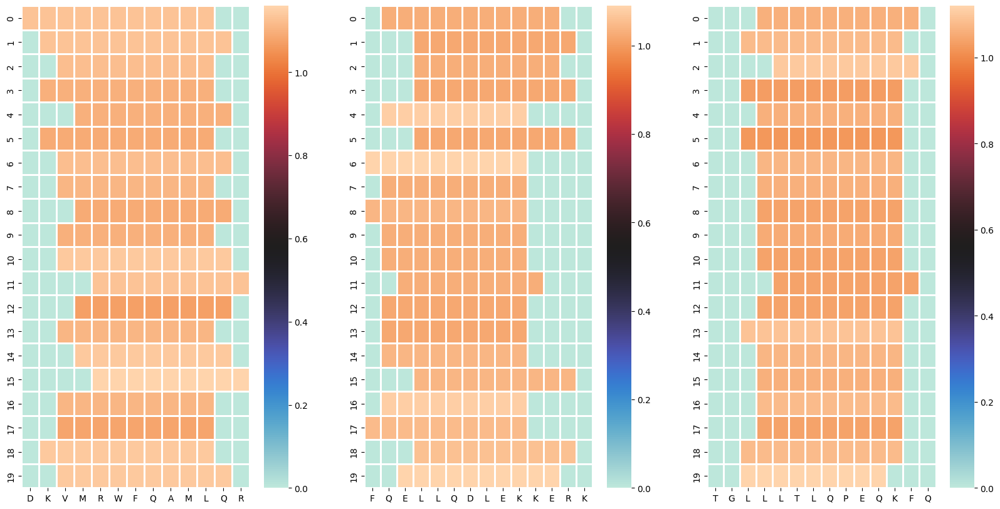

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
# sns.set(font_scale=1.0)
fig, axes = plt.subplots(nrows= 1, ncols=3, figsize=(20, 10))
for df, ax in zip(list(per_selected_peptide_df.values())[3:6], axes.reshape(-1)):
    target_df = df[:-1]
    # target_df = df.ilo|c[np.r_[0:15, -1:-0]]
    sns.heatmap(target_df, annot=False, cmap=sns.color_palette("icefire", as_cmap=True, ), ax=ax, linewidths=1)


## check viterbi

In [18]:
[ item[1].name for item in model.viterbi(allele_peptides[0])[1]]

['grouped_model-start',
 's023',
 's002',
 's005',
 's006',
 's010',
 's013',
 's017',
 's020',
 's026',
 's031',
 's031',
 's031',
 's031',
 'grouped_model-end']

In [46]:
pd.DataFrame(model.forward(allele_peptides[0])[:, 20:])

,0,1,2,3,4,5,6,7,8,9,10
0,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,-inf,0.0,-inf
1,-inf,-15.531407,-7.958444,-inf,-inf,-3.417573,-3.199682,-inf,-inf,-inf,-inf
2,-inf,-9.712337,-10.123450,-inf,-inf,-6.702326,-6.045836,-inf,-inf,-inf,-inf
3,-inf,-12.997090,-12.969604,-inf,-inf,-9.987079,-8.891990,-inf,-inf,-inf,-inf
4,-inf,-11.780247,-10.763989,-inf,-inf,-13.327280,-13.540482,-inf,-inf,-inf,-inf
5,-inf,-19.622044,-20.464250,-inf,-inf,-16.901675,-15.815416,-inf,-inf,-inf,-inf
6,-inf,-23.196439,-22.739184,-inf,-inf,-20.476070,-18.090350,-inf,-inf,-inf,-inf
7,-inf,-22.269238,-19.962349,-inf,-inf,-23.816271,-22.738842,-inf,-inf,-inf,-inf
8,-27.030413,-25.609439,-24.610840,-inf,-inf,-27.156472,-27.387333,-inf,-inf,-inf,-inf
9,-30.446071,-33.451233,-29.380648,-23.516893,-30.046585,-30.933876,-30.867547,-inf,-inf,-inf,-26.914600


# Group models based on predictions
We got all the start predictions from all models. Now we want to group these models. (since we expect that models have disagrement)
We want to cluster columns based on how similar are predictions for the whole training data

In [47]:
total_df.columns

Index(['simplified_path', 'core_start_0', 'core_end_0', 'prob_0',
       'core_start_1', 'core_end_1', 'prob_1', 'core_start_2', 'core_end_2',
       'prob_2',
       ...
       'core_start_32', 'core_end_32', 'prob_32', 'core_start_33',
       'core_end_33', 'prob_33', 'core_start_34', 'core_end_34', 'prob_34',
       'peptide'],
      dtype='object', length=107)

In [48]:
models_predictions = total_df[[f"core_start_{i}" for i in range(RUNS)]]

In [49]:
corr_matrix = np.corrcoef(models_predictions,  rowvar=False)

In [50]:
corr_matrix.shape

(35, 35)

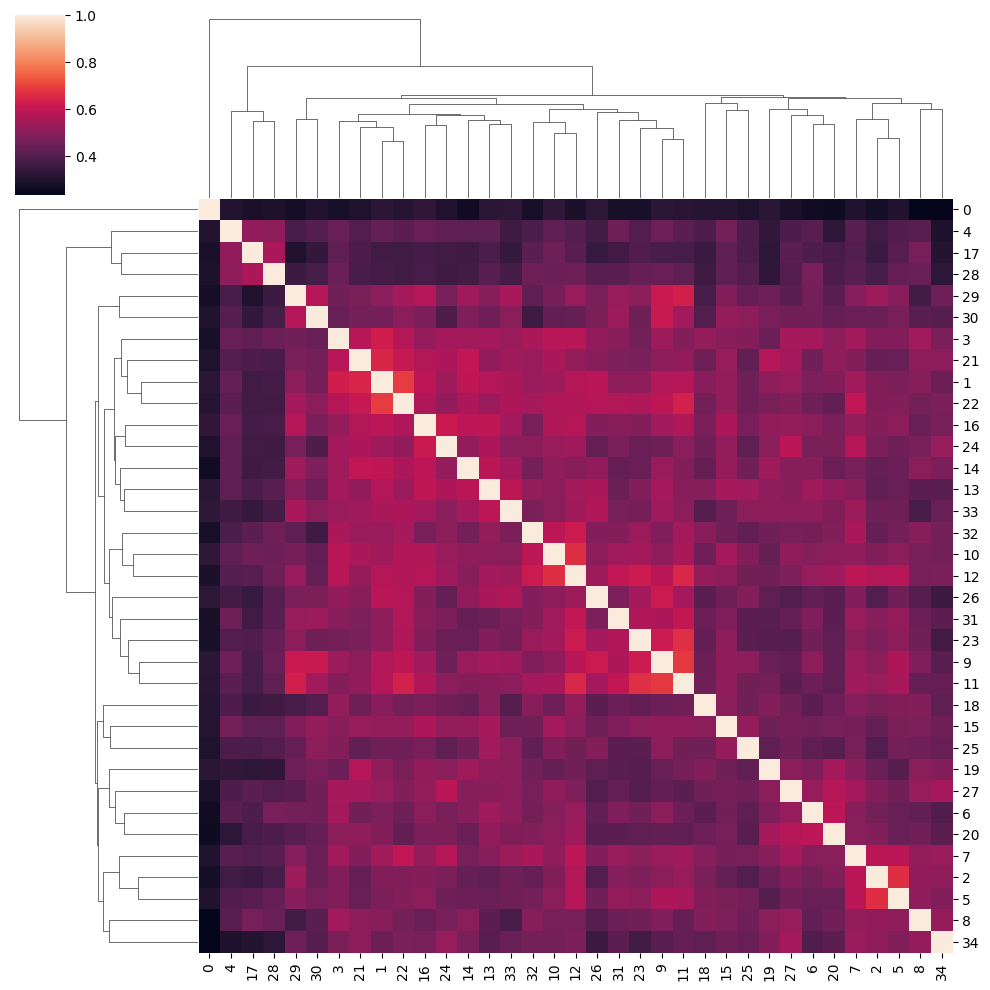

In [51]:
import seaborn as sns
clustergrid = sns.clustermap(corr_matrix)

## Merge different start predictions into single column (Take mean for now)

In [52]:
from sklearn.cluster import FeatureAgglomeration
distance_threshold = 150

agglo = FeatureAgglomeration(n_clusters=None, metric='euclidean', linkage='ward', pooling_func=np.mean, distance_threshold=distance_threshold)

In [53]:
result_start_df = agglo.fit_transform(models_predictions)


In [54]:
models_predictions

,core_start_0,core_start_1,core_start_2,core_start_3,core_start_4,core_start_5,core_start_6,core_start_7,core_start_8,core_start_9,...,core_start_25,core_start_26,core_start_27,core_start_28,core_start_29,core_start_30,core_start_31,core_start_32,core_start_33,core_start_34
AAALEELLKEYHS,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3,0,0,3,0
AAEILFDEVLTFAKDH,2,4,1,5,5,4,5,4,4,4,...,5,5,2,5,5,5,1,4,5,4
AAEKLFGNMEGDCPS,2,2,1,1,1,1,2,1,4,1,...,5,2,2,1,1,5,1,1,2,3
AAERAIEKMNGML,2,1,1,2,1,1,2,1,1,1,...,1,2,2,1,1,2,1,2,2,1
AAERAIEKMNGMLL,2,1,4,2,1,1,2,4,1,4,...,1,4,2,1,5,2,1,2,2,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYTEFTPTEKDEY,2,1,0,0,1,1,1,1,0,1,...,1,1,2,0,1,1,0,1,1,1
YYTEFTPTEKDEYA,2,1,0,0,1,1,1,1,0,1,...,1,4,2,0,1,1,0,1,1,1
YYTEFTPTEKDEYAC,2,1,0,0,1,1,1,1,0,1,...,1,4,2,0,1,4,0,1,1,1
YYTEFTPTEKDEYACR,2,1,0,0,1,1,1,1,0,1,...,1,4,2,0,1,4,0,1,1,1


In [55]:
result_start_df

array([[0.25      , 0.6       , 0.4       , 0.5       ],
       [3.75      , 4.26666667, 3.6       , 3.83333333],
       [1.25      , 2.26666667, 2.2       , 1.66666667],
       ...,
       [2.        , 1.2       , 0.9       , 1.33333333],
       [0.75      , 1.2       , 0.9       , 1.33333333],
       [0.75      , 1.2       , 1.2       , 1.83333333]])

In [56]:
clustered_features = pd.DataFrame({"cluster": agglo.labels_})

clustered_features['model'] = models_predictions.columns


unique_labels_counts = clustered_features.cluster.value_counts().sort_values(ascending=False)
unique_labels_counts

1    15
2    10
3     6
0     4
Name: cluster, dtype: int64

In [57]:
clustered_features

,cluster,model
0,0,core_start_0
1,1,core_start_1
2,2,core_start_2
3,1,core_start_3
4,0,core_start_4
5,2,core_start_5
6,2,core_start_6
7,2,core_start_7
8,2,core_start_8
9,3,core_start_9


In [58]:
clustered_features.style.set_properties(subset=['ad_description'], **{'width-min': '600px', 'width-max': '600px'})

cluster_descriptions = clustered_features.groupby('cluster').agg(lambda x: " ".join(x.values))
cluster_descriptions['len'] = unique_labels_counts
cluster_descriptions.sort_values(by='len', ascending=False)

,model,len
cluster,,
1,core_start_1 core_start_3 core_start_10 core_s...,15
2,core_start_2 core_start_5 core_start_6 core_st...,10
3,core_start_9 core_start_11 core_start_23 core_...,6
0,core_start_0 core_start_4 core_start_17 core_s...,4


In [59]:
cluster_descriptions.loc[0]['len']

4

In [60]:
cluster_descriptions.loc[1]['model'].split(' ')

['core_start_1',
 'core_start_3',
 'core_start_10',
 'core_start_12',
 'core_start_13',
 'core_start_14',
 'core_start_15',
 'core_start_16',
 'core_start_21',
 'core_start_22',
 'core_start_24',
 'core_start_25',
 'core_start_26',
 'core_start_32',
 'core_start_33']

In [61]:
model_to_cluster = dict(clustered_features['cluster'])

In [62]:
cluster_to_start_columns = {i : total_df[cluster_descriptions.loc[i]['model'].split(' ')] for i in cluster_descriptions.index}


In [63]:
cluster_to_start_columns[0]

,core_start_0,core_start_4,core_start_17,core_start_28
AAALEELLKEYHS,1,0,0,0
AAEILFDEVLTFAKDH,2,5,3,5
AAEKLFGNMEGDCPS,2,1,1,1
AAERAIEKMNGML,2,1,1,1
AAERAIEKMNGMLL,2,1,1,1
...,...,...,...,...
YYTEFTPTEKDEY,2,1,0,0
YYTEFTPTEKDEYA,2,1,0,0
YYTEFTPTEKDEYAC,2,1,5,0
YYTEFTPTEKDEYACR,2,1,0,0


# Add mean probability for cluster for each peptide

In [ ]:
from collections import defaultdict
cluster_to_prob_column_names = defaultdict(list)
cluster_to_end_column_names = defaultdict(list)

for cluster in cluster_descriptions.index:
    print(cluster)
    total_df[f'cluster_prob_{cluster}'] = 0
    
# calculate mean for predictions for given cluster of models to 
for i in range(RUNS):
    total_df[f'cluster_prob_{model_to_cluster[i]}'] += total_df[f'prob_{i}']
    cluster_to_prob_column_names[model_to_cluster[i]].append(f'prob_{i}')
    cluster_to_end_column_names[model_to_cluster[i]].append(f'core_end_{i}')

for cluster in cluster_descriptions.index:
    print(cluster)
    total_df[f'cluster_prob_{cluster}'] = total_df[f'cluster_prob_{cluster}'] / cluster_descriptions.loc[cluster]['len']
    
total_df['max_mean_prob_cluster'] =   total_df[[f'cluster_prob_{cluster}' for cluster in cluster_descriptions.index]].idxmax(axis=1).str.split('_').map(lambda x : int(x[-1]))

In [36]:
cluster_to_prob_columns = {i : total_df[cluster_to_prob_column_names[i]] for i in cluster_to_prob_column_names}
cluster_to_end_columns = {i : total_df[cluster_to_end_column_names[i]] for i in cluster_to_end_column_names}

## Add entropy value for cluster for each column

In [37]:
def mean_predictive_entropy(predictions):
    entropy = np.mean(-np.sum(np.exp(predictions)*predictions, axis=1)/predictions.shape[1])
    return entropy

def predictive_entropy(predictions):
    entropy = -np.sum(np.exp(predictions)*predictions, axis=1)/predictions.shape[1]
    return entropy

print(mean_predictive_entropy(cluster_to_prob_columns[0]))
print(mean_predictive_entropy(cluster_to_prob_columns[1]))
# print(mean_predictive_entropy(cluster_to_prob_columns[2]))


cluster_to_start_entropy_df = {i: predictive_entropy(cluster_to_prob_columns[i]) for i in cluster_to_prob_columns.keys()}

0.15486806679539525
0.15444581202400148


In [38]:

df_concat = pd.concat(cluster_to_start_entropy_df.values(), axis=1)
min_entropy_clusters = df_concat.idxmin(axis=1)
df_concat.columns = [f'cluster_entropy_{cluster}' for cluster in df_concat.columns ]
df_concat['min_entropy_cluster'] = min_entropy_clusters

In [39]:
df_concat

,cluster_entropy_0,cluster_entropy_1,min_entropy_cluster
AAALEELLKEYHS,0.213391,0.183023,1
AAEILFDEVLTFAKDH,0.150160,0.150744,0
AAEKLFGNMEGDCPS,0.142255,0.145106,0
AAERAIEKMNGML,0.142351,0.137281,1
AAERAIEKMNGMLL,0.139239,0.135286,1
...,...,...,...
YYTEFTPTEKDEY,0.160571,0.158986,1
YYTEFTPTEKDEYA,0.155867,0.155744,1
YYTEFTPTEKDEYAC,0.151871,0.152974,0
YYTEFTPTEKDEYACR,0.148439,0.150580,0


In [40]:
df_concat['min_entropy_cluster']

AAALEELLKEYHS         1
AAEILFDEVLTFAKDH      0
AAEKLFGNMEGDCPS       0
AAERAIEKMNGML         1
AAERAIEKMNGMLL        1
                     ..
YYTEFTPTEKDEY         1
YYTEFTPTEKDEYA        1
YYTEFTPTEKDEYAC       0
YYTEFTPTEKDEYACR      0
YYTEFTPTEKDEYACRVN    0
Name: min_entropy_cluster, Length: 5640, dtype: int64

In [41]:
df_concat.idxmin(axis=1).value_counts()

min_entropy_cluster    2914
cluster_entropy_1      2726
dtype: int64

In [42]:
final_df = pd.concat([total_df, df_concat], axis=1)

## Set core start based on selected cluster

In [43]:
selected_cluster_column = 'max_mean_prob_cluster'
final_df['core_start'] = 0
final_df['core_end'] = 0
for cluster in cluster_descriptions.index:
    index_peptides = final_df[final_df[selected_cluster_column] == cluster].index
    start_values = cluster_to_start_columns[cluster]
    end_values = cluster_to_end_columns[cluster]
    final_df.loc[index_peptides, 'core_start'] = start_values.loc[index_peptides].mean(axis=1).round().astype(int).values
    final_df.loc[index_peptides, 'core_end'] = end_values.loc[index_peptides].mean(axis=1).round().astype(int).values
final_df['core_peptide'] = final_df.apply(lambda row: row.name[row['core_start']:row['core_end'] + 1], axis=1)
final_df['core_len'] = final_df['core_peptide'].str.len()

In [44]:
final_df['core_len'].value_counts()

9     3961
10    1640
11      39
Name: core_len, dtype: int64

In [45]:
final_df['core_start']

AAALEELLKEYHS         1
AAEILFDEVLTFAKDH      5
AAEKLFGNMEGDCPS       2
AAERAIEKMNGML         2
AAERAIEKMNGMLL        2
                     ..
YYTEFTPTEKDEY         2
YYTEFTPTEKDEYA        2
YYTEFTPTEKDEYAC       1
YYTEFTPTEKDEYACR      1
YYTEFTPTEKDEYACRVN    1
Name: core_start, Length: 5640, dtype: int64

In [46]:
final_df['core_end']

AAALEELLKEYHS         10
AAEILFDEVLTFAKDH      13
AAEKLFGNMEGDCPS       10
AAERAIEKMNGML         10
AAERAIEKMNGMLL        10
                      ..
YYTEFTPTEKDEY         11
YYTEFTPTEKDEYA        11
YYTEFTPTEKDEYAC        9
YYTEFTPTEKDEYACR       9
YYTEFTPTEKDEYACRVN     9
Name: core_end, Length: 5640, dtype: int64

In [47]:
final_df[final_df.columns[-15:]]

,prob_18,core_start_19,core_end_19,prob_19,peptide,cluster_prob_0,cluster_prob_1,max_mean_prob_cluster,cluster_entropy_0,cluster_entropy_1,min_entropy_cluster,core_start,core_end,core_peptide,core_len
AAALEELLKEYHS,-2.430845,0,8,-2.688333,AAALEELLKEYHS,-2.686370,-2.434457,1,0.213391,0.183023,1,1,10,AALEELLKEY,10
AAEILFDEVLTFAKDH,-2.967846,5,13,-2.976110,AAEILFDEVLTFAKDH,-2.986304,-2.992402,0,0.150160,0.150744,0,5,13,FDEVLTFAK,9
AAEKLFGNMEGDCPS,-3.080815,2,10,-3.010999,AAEKLFGNMEGDCPS,-3.043731,-3.072942,0,0.142255,0.145106,0,2,10,EKLFGNMEG,9
AAERAIEKMNGML,-3.056488,1,9,-3.157246,AAERAIEKMNGML,-3.125732,-3.071815,1,0.142351,0.137281,1,2,10,ERAIEKMNG,9
AAERAIEKMNGMLL,-3.085292,1,9,-3.177981,AAERAIEKMNGMLL,-3.147163,-3.104502,1,0.139239,0.135286,1,2,10,ERAIEKMNG,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYTEFTPTEKDEY,-2.824811,1,9,-2.913929,YYTEFTPTEKDEY,-2.905629,-2.890937,1,0.160571,0.158986,1,2,11,TEFTPTEKDE,10
YYTEFTPTEKDEYA,-2.870164,1,9,-2.944750,YYTEFTPTEKDEYA,-2.936947,-2.936230,1,0.155867,0.155744,1,2,11,TEFTPTEKDE,10
YYTEFTPTEKDEYAC,-2.909469,1,9,-2.971461,YYTEFTPTEKDEYAC,-2.964090,-2.975485,0,0.151871,0.152974,0,1,9,YTEFTPTEK,9
YYTEFTPTEKDEYACR,-2.943861,1,9,-2.994833,YYTEFTPTEKDEYACR,-2.987840,-3.009833,0,0.148439,0.150580,0,1,9,YTEFTPTEK,9


In [48]:
total_df[['cluster_prob_0', 'cluster_prob_1', 'cluster_prob_2']]

KeyError: "['cluster_prob_2'] not in index"

In [71]:
final_df['max_mean_prob_cluster'].value_counts()

0    2921
1    2719
Name: max_mean_prob_cluster, dtype: int64

In [72]:
final_df['min_entropy_cluster'].value_counts()

0    2914
1    2726
Name: min_entropy_cluster, dtype: int64

In [73]:
dict(cluster_descriptions['model'])

{0: 'core_start_2 core_start_3 core_start_4 core_start_5 core_start_6 core_start_7 core_start_8 core_start_9 core_start_10 core_start_11 core_start_12 core_start_13 core_start_14 core_start_15 core_start_16 core_start_17 core_start_19',
 1: 'core_start_0 core_start_1 core_start_18'}

NameError: name 'agglo' is not defined

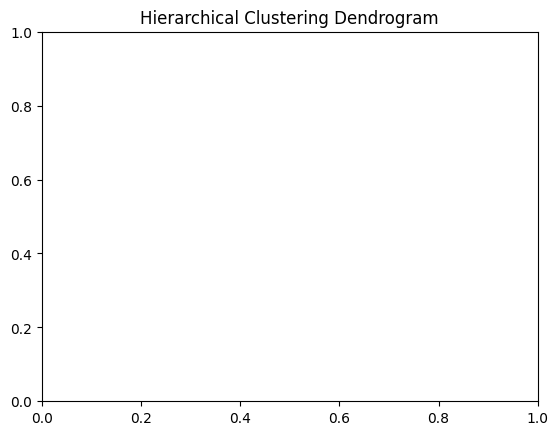

In [1]:
import numpy as np

from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix,leaf_rotation=90,  **kwargs)
plt.title("Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(agglo, truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.axhline(y=distance_threshold, color='r', linestyle='-')
plt.show()

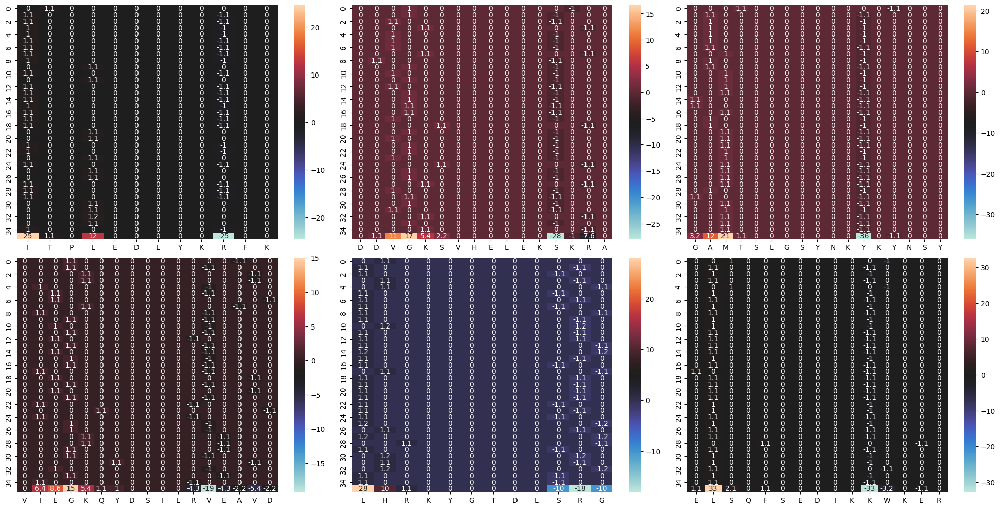

In [23]:
fig, axes = plt.subplots(nrows= 2, ncols=3, figsize=(20, 10))
for df, ax in zip(per_selected_peptide_df.values(), axes.reshape(-1)):
    sns.heatmap(df - df.shift(periods=1, axis="columns", fill_value=0), annot=True, cmap=sns.color_palette("icefire", as_cmap=True), ax=ax)
fig.tight_layout(pad=0.5)


In [32]:
df = total_df.sample(50)

In [33]:
df['simplified_path'] = df['simplified_path'].map(lambda x: np.round(x, 2))

In [34]:
df

,simplified_path,peptide
EAARVAEQLRAYL,"[0.0, 3.24, 17.59, 32.54, 32.54, 32.54, 32.54,...",EAARVAEQLRAYL
KILKKHDKILETSR,"[2.3, 5.58, 14.66, 26.96, 33.89, 33.89, 33.89,...",KILKKHDKILETSR
LAQMFSDMVLKDGFQPS,"[0.0, 6.78, 24.72, 31.69, 34.06, 34.06, 34.06,...",LAQMFSDMVLKDGFQPS
RQLTFEEIAKSAKI,"[0.0, 7.37, 22.26, 31.82, 31.82, 31.82, 31.82,...",RQLTFEEIAKSAKI
LRKKAQEVLLNSP,"[0.0, 11.12, 17.67, 32.83, 32.83, 32.83, 32.83...",LRKKAQEVLLNSP
KTIENFLVVNKERIF,"[0.0, 0.0, 6.37, 20.1, 30.86, 31.92, 31.92, 31...",KTIENFLVVNKERIF
AAKVFESIGKFGLA,"[0.0, 7.38, 26.37, 32.04, 32.04, 32.04, 32.04,...",AAKVFESIGKFGLA
DIKFLPFKVVEKKTK,"[0.0, 0.0, 0.0, 7.4, 21.24, 31.78, 31.78, 31.7...",DIKFLPFKVVEKKTK
SPVFIAFRSSTKKSVQY,"[0.0, 6.58, 6.58, 13.06, 20.73, 31.55, 32.61, ...",SPVFIAFRSSTKKSVQY
YPGSQLDILIDQGKD,"[0.0, 0.0, 1.14, 8.92, 16.58, 22.85, 32.48, 32...",YPGSQLDILIDQGKD


In [77]:
threshold = 7.57 #threshold value for core call

In [37]:
 total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > 0)[0]).apply(lambda x: x[0] if len(x) > 0 else 0).value_counts()

1    2851
2    1300
0     840
3     463
4     159
5      24
6       3
Name: simplified_path, dtype: int64

In [78]:
total_df['core_start'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[0] if len(x) > 0 else 0)

total_df['core_end'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[-1] if len(x)> 0 else 1)
total_df['core_len'] = total_df['core_end'] - total_df['core_start'] + 1
total_df['peptide_len'] = total_df.index.str.len()
total_df['core_peptide'] =total_df.apply(lambda row: row.name[row['core_start']:row['core_end'] + 1], axis=1)
total_df = total_df[~total_df.index.duplicated(keep='first')]
total_df['simplified_path'] = total_df['simplified_path'].apply(lambda x: np.round(x.astype(float),2))
total_df['core_path'] = total_df.apply(lambda row: row['simplified_path'][row['core_start']:row['core_end'] + 1] , axis=1)


In [79]:
total_df

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
AAAAAAAAAAKAA,"[1.05, 13.67, 14.73, 15.76, 15.76, 15.76, 15.7...",AAAAAAAAAAKAA,1,9,9,13,AAAAAAAAA,"[13.67, 14.73, 15.76, 15.76, 15.76, 15.76, 15...."
AAAAAAAGAFAGRR,"[3.21, 9.37, 13.57, 14.61, 15.67, 15.67, 15.67...",AAAAAAAGAFAGRR,1,9,9,14,AAAAAAGAF,"[9.37, 13.57, 14.61, 15.67, 15.67, 15.67, 15.6..."
AAAEVAGQFVIKLTHD,"[0.0, 2.06, 4.18, 8.35, 14.59, 15.6, 15.6, 15....",AAAEVAGQFVIKLTHD,3,11,9,16,EVAGQFVIK,"[8.35, 14.59, 15.6, 15.6, 15.6, 15.6, 15.6, 13..."
AAAIQTMSLDAER,"[1.03, 2.08, 7.22, 15.39, 15.39, 15.39, 15.39,...",AAAIQTMSLDAER,3,11,9,13,IQTMSLDAE,"[15.39, 15.39, 15.39, 15.39, 15.39, 15.39, 14...."
AAAIQTMSLDAERRK,"[1.03, 2.08, 5.18, 12.35, 14.44, 15.47, 15.47,...",AAAIQTMSLDAERRK,3,11,9,15,IQTMSLDAE,"[12.35, 14.44, 15.47, 15.47, 15.47, 15.47, 14...."
...,...,...,...,...,...,...,...,...
YVVVGAQRDAWGPG,"[2.06, 5.2, 13.46, 15.55, 15.55, 15.55, 15.55,...",YVVVGAQRDAWGPG,2,10,9,14,VVGAQRDAW,"[13.46, 15.55, 15.55, 15.55, 15.55, 15.55, 15...."
YVWGFYPAEVTITWRKN,"[1.02, 3.09, 5.16, 8.25, 11.3, 15.45, 15.45, 1...",YVWGFYPAEVTITWRKN,3,11,9,17,GFYPAEVTI,"[8.25, 11.3, 15.45, 15.45, 15.45, 15.45, 14.43..."
YWASTRESGVPD,"[3.17, 11.28, 14.47, 15.48, 15.48, 15.48, 15.4...",YWASTRESGVPD,1,9,9,12,WASTRESGV,"[11.28, 14.47, 15.48, 15.48, 15.48, 15.48, 15...."
YYTEFTPTEKD,"[9.24, 15.37, 15.37, 15.37, 15.37, 15.37, 15.3...",YYTEFTPTEKD,0,8,9,11,YYTEFTPTE,"[9.24, 15.37, 15.37, 15.37, 15.37, 15.37, 15.3..."


In [25]:
total_df.core_len.value_counts()

AttributeError: 'DataFrame' object has no attribute 'core_len'

In [81]:
if TEST_PDB_CORES:
    df = total_df.copy()
    df['true_label'] = true_labels
    df['netmhcpan3.2'] = netmhcpan

In [82]:
df[['peptide', 'core_peptide', 'true_label', 'netmhcpan3.2']]

KeyError: "['core_peptide', 'true_label', 'netmhcpan3.2'] not in index"

## Motifs for multiple alleles

In [83]:
allele1_peptides = np.unique(np.concatenate([per_allele_per_kfold_per_length_binders_train_old[OLD_ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS]))
# allele2_peptides = np.unique(np.concatenate([per_allele_per_kfold_per_length_binders_train_old[OLD_ALLELES[1]][0][target_length] for target_length in TARGET_LENGTHS]))

In [84]:
total_df.loc[allele1_peptides,'allele'] = OLD_ALLELES[0]
# total_df.loc[allele2_peptides,'allele'] = OLD_ALLELES[1]

In [85]:
total_df.allele.value_counts(dropna=False)

HLA-DQA1*05:01/DQB1*02:01    3014
Name: allele, dtype: int64


## Show motifs for cores of different lengths

In [86]:
import seaborn as sns
sns.set_theme(style="white")
def make_logo_for_data(binders_array, name, ax=None, mark_left=None, mark_right=None):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
    if mark_left:
        mark_left -= 0.5
        ww_logo.ax.axvline(x=mark_left, color='purple', lw=2)
    if mark_right:
        mark_right -= 0.5
        ww_logo.ax.axvline(x=mark_right, color='purple', lw=2)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

In [87]:
total_df.core_len.value_counts()

9     2910
10     104
Name: core_len, dtype: int64

In [88]:
total_df.core_start.value_counts()

2    773
3    756
1    507
4    502
5    265
6    128
7     50
8     16
0     14
9      3
Name: core_start, dtype: int64

In [89]:
def restricted_motif(df, core_len=None, peptide_len=None, core_start=None, use_peptides=True, peptide_column='peptide', mark_left=None, mark_right=None):
    title_string = ""
    if core_len is not None:
        df = df[df.core_len == core_len]
        title_string = f"{title_string} core len {core_len}"
    if core_start is not None:
        df = df[df.core_start == core_start]
        title_string = f"{title_string} start {core_start}"
    if peptide_len:
        df = df[df.peptide_len == peptide_len]
        title_string = f"{title_string} pep len {peptide_len}"
    peptides = df.index.values
    core_starts = df['core_start'].values
    core_ends = df['core_end'].values
    cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
    make_logo_for_data(cores, f"cores {title_string}")

    if use_peptides:
        peptides_to_draw = df[peptide_column]
        #ensure same size
        len_supossed_to_be = len(peptides_to_draw)
        df = df[df[peptide_column].str.len() == df[peptide_column].str.len().max()]
        peptides_to_draw = df[peptide_column]
        len_that_will_be_used = len(peptides_to_draw)
        if len_supossed_to_be != len_that_will_be_used:
            print(f"found different lengths. Took max. deleted {len_supossed_to_be - len_that_will_be_used} peptides")
        make_logo_for_data(peptides_to_draw, f"Pep {title_string}", mark_left=mark_left, mark_right=mark_right, )
    data_used = df
    return data_used



C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path,allele
AAAAAAAAAAKAA,"[1.05, 13.67, 14.73, 15.76, 15.76, 15.76, 15.7...",AAAAAAAAAAKAA,1,9,9,13,AAAAAAAAA,"[13.67, 14.73, 15.76, 15.76, 15.76, 15.76, 15....",HLA-DQA1*05:01/DQB1*02:01
AAAAAAAGAFAGRR,"[3.21, 9.37, 13.57, 14.61, 15.67, 15.67, 15.67...",AAAAAAAGAFAGRR,1,9,9,14,AAAAAAGAF,"[9.37, 13.57, 14.61, 15.67, 15.67, 15.67, 15.6...",HLA-DQA1*05:01/DQB1*02:01
AAAEVAGQFVIKLTHD,"[0.0, 2.06, 4.18, 8.35, 14.59, 15.6, 15.6, 15....",AAAEVAGQFVIKLTHD,3,11,9,16,EVAGQFVIK,"[8.35, 14.59, 15.6, 15.6, 15.6, 15.6, 15.6, 13...",HLA-DQA1*05:01/DQB1*02:01
AAAIQTMSLDAER,"[1.03, 2.08, 7.22, 15.39, 15.39, 15.39, 15.39,...",AAAIQTMSLDAER,3,11,9,13,IQTMSLDAE,"[15.39, 15.39, 15.39, 15.39, 15.39, 15.39, 14....",HLA-DQA1*05:01/DQB1*02:01
AAAIQTMSLDAERRK,"[1.03, 2.08, 5.18, 12.35, 14.44, 15.47, 15.47,...",AAAIQTMSLDAERRK,3,11,9,15,IQTMSLDAE,"[12.35, 14.44, 15.47, 15.47, 15.47, 15.47, 14....",HLA-DQA1*05:01/DQB1*02:01
...,...,...,...,...,...,...,...,...,...
YVVVGAQRDAWGPG,"[2.06, 5.2, 13.46, 15.55, 15.55, 15.55, 15.55,...",YVVVGAQRDAWGPG,2,10,9,14,VVGAQRDAW,"[13.46, 15.55, 15.55, 15.55, 15.55, 15.55, 15....",HLA-DQA1*05:01/DQB1*02:01
YVWGFYPAEVTITWRKN,"[1.02, 3.09, 5.16, 8.25, 11.3, 15.45, 15.45, 1...",YVWGFYPAEVTITWRKN,3,11,9,17,GFYPAEVTI,"[8.25, 11.3, 15.45, 15.45, 15.45, 15.45, 14.43...",HLA-DQA1*05:01/DQB1*02:01
YWASTRESGVPD,"[3.17, 11.28, 14.47, 15.48, 15.48, 15.48, 15.4...",YWASTRESGVPD,1,9,9,12,WASTRESGV,"[11.28, 14.47, 15.48, 15.48, 15.48, 15.48, 15....",HLA-DQA1*05:01/DQB1*02:01
YYTEFTPTEKD,"[9.24, 15.37, 15.37, 15.37, 15.37, 15.37, 15.3...",YYTEFTPTEKD,0,8,9,11,YYTEFTPTE,"[9.24, 15.37, 15.37, 15.37, 15.37, 15.37, 15.3...",HLA-DQA1*05:01/DQB1*02:01


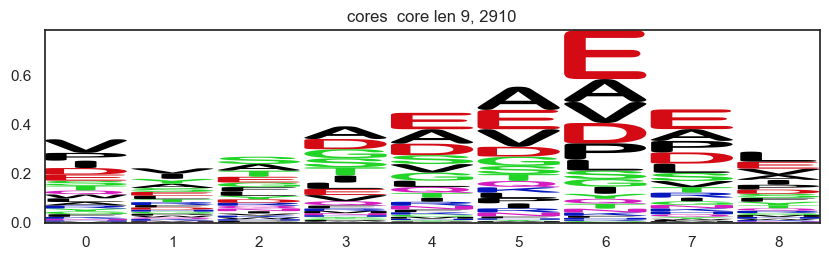

In [90]:
restricted_motif(total_df[total_df.allele == OLD_ALLELES[0]], core_len=9, use_peptides=False)

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


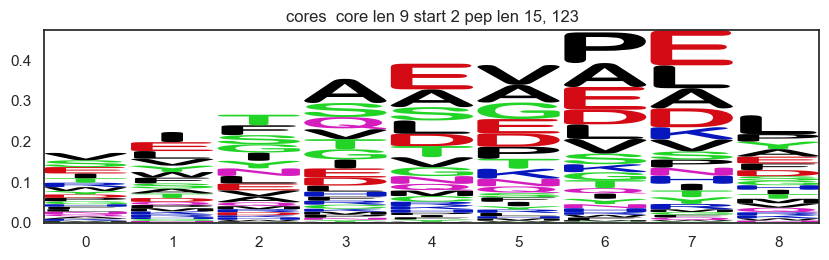

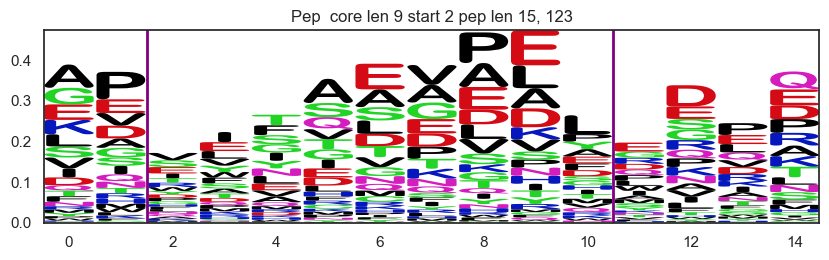

In [92]:
target_peptide_len = 15
target_core_len = 9
core_start = 2
df = restricted_motif(total_df,
                      peptide_len=target_peptide_len, core_len=target_core_len,
                      use_peptides=True,
                          core_start=core_start,mark_left=core_start, mark_right=core_start+target_core_len
                      )




In [93]:
df

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path,allele
ADEIYDCKVEHWGLD,"[0.0, 2.04, 8.06, 15.12, 15.12, 15.12, 15.12, ...",ADEIYDCKVEHWGLD,2,10,9,15,EIYDCKVEH,"[8.06, 15.12, 15.12, 15.12, 15.12, 15.12, 15.1...",HLA-DQA1*05:01/DQB1*02:01
ADGYSADLPLPLPIR,"[2.12, 4.22, 8.36, 14.67, 15.7, 15.7, 15.7, 15...",ADGYSADLPLPLPIR,2,10,9,15,GYSADLPLP,"[8.36, 14.67, 15.7, 15.7, 15.7, 15.7, 15.7, 13...",HLA-DQA1*05:01/DQB1*02:01
ADITQVTVLDVPDPP,"[0.0, 3.18, 9.44, 9.44, 11.52, 15.67, 15.67, 1...",ADITQVTVLDVPDPP,2,10,9,15,ITQVTVLDV,"[9.44, 9.44, 11.52, 15.67, 15.67, 15.67, 15.67...",HLA-DQA1*05:01/DQB1*02:01
ADKASASAPAPASAT,"[0.0, 4.11, 9.38, 11.47, 14.6, 15.61, 15.61, 1...",ADKASASAPAPASAT,2,10,9,15,KASASAPAP,"[9.38, 11.47, 14.6, 15.61, 15.61, 15.61, 15.61...",HLA-DQA1*05:01/DQB1*02:01
AESWNSQKDILEDRR,"[1.01, 4.04, 12.18, 14.22, 15.24, 15.24, 15.24...",AESWNSQKDILEDRR,2,10,9,15,SWNSQKDIL,"[12.18, 14.22, 15.24, 15.24, 15.24, 15.24, 15....",HLA-DQA1*05:01/DQB1*02:01
...,...,...,...,...,...,...,...,...,...
VQDINDNPPEFLHET,"[1.06, 3.08, 12.38, 14.45, 14.45, 15.52, 15.52...",VQDINDNPPEFLHET,2,10,9,15,DINDNPPEF,"[12.38, 14.45, 14.45, 15.52, 15.52, 15.52, 15....",HLA-DQA1*05:01/DQB1*02:01
VTHEGSTVEKTVAPT,"[0.0, 5.23, 9.33, 11.42, 12.47, 15.63, 15.63, ...",VTHEGSTVEKTVAPT,2,10,9,15,HEGSTVEKT,"[9.33, 11.42, 12.47, 15.63, 15.63, 15.63, 15.6...",HLA-DQA1*05:01/DQB1*02:01
WEEQLAAAKAQQEQE,"[0.0, 7.17, 8.18, 11.26, 14.34, 15.4, 15.4, 15...",WEEQLAAAKAQQEQE,2,10,9,15,EQLAAAKAQ,"[8.18, 11.26, 14.34, 15.4, 15.4, 15.4, 15.4, 1...",HLA-DQA1*05:01/DQB1*02:01
YIFYTFSTVHPIPDE,"[1.04, 3.1, 9.28, 13.33, 13.33, 15.4, 15.4, 15...",YIFYTFSTVHPIPDE,2,10,9,15,FYTFSTVHP,"[9.28, 13.33, 13.33, 15.4, 15.4, 15.4, 15.4, 1...",HLA-DQA1*05:01/DQB1*02:01


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


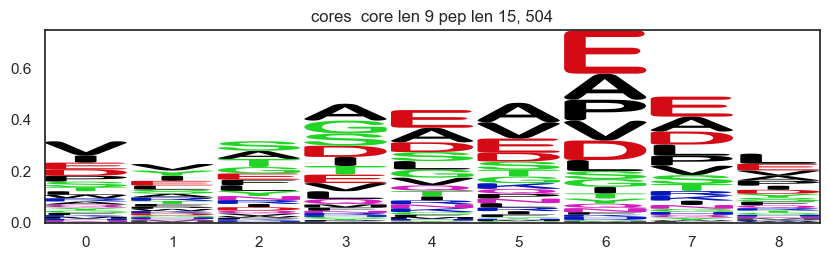

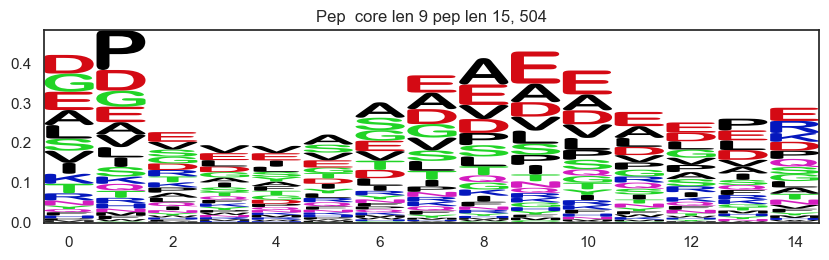

In [94]:
target_peptide_len = 15
target_core_len = 9
# core_start = 6
df = restricted_motif(total_df,
                      # core_start=core_start,
                      core_len=target_core_len, peptide_len=target_peptide_len, use_peptides=True)



In [95]:
df

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path,allele
AAAIQTMSLDAERRK,"[1.03, 2.08, 5.18, 12.35, 14.44, 15.47, 15.47,...",AAAIQTMSLDAERRK,3,11,9,15,IQTMSLDAE,"[12.35, 14.44, 15.47, 15.47, 15.47, 15.47, 14....",HLA-DQA1*05:01/DQB1*02:01
AAANAAAGAAENAFR,"[0.0, 2.09, 7.24, 11.35, 14.46, 15.5, 15.5, 15...",AAANAAAGAAENAFR,3,11,9,15,NAAAGAAEN,"[11.35, 14.46, 15.5, 15.5, 15.5, 15.5, 15.5, 1...",HLA-DQA1*05:01/DQB1*02:01
AAEEPNAAVPDEIPP,"[0.0, 2.1, 4.14, 9.38, 14.42, 15.45, 15.45, 15...",AAEEPNAAVPDEIPP,3,11,9,15,EPNAAVPDE,"[9.38, 14.42, 15.45, 15.45, 15.45, 15.45, 15.4...",HLA-DQA1*05:01/DQB1*02:01
AASSYLSLTPEQWKS,"[0.0, 3.08, 5.14, 10.24, 15.25, 15.25, 15.25, ...",AASSYLSLTPEQWKS,3,11,9,15,SYLSLTPEQ,"[10.24, 15.25, 15.25, 15.25, 15.25, 15.25, 15....",HLA-DQA1*05:01/DQB1*02:01
ADEIYDCKVEHWGLD,"[0.0, 2.04, 8.06, 15.12, 15.12, 15.12, 15.12, ...",ADEIYDCKVEHWGLD,2,10,9,15,EIYDCKVEH,"[8.06, 15.12, 15.12, 15.12, 15.12, 15.12, 15.1...",HLA-DQA1*05:01/DQB1*02:01
...,...,...,...,...,...,...,...,...,...
YPEEVSSMVLTKMKE,"[0.0, 4.07, 6.21, 12.33, 15.41, 15.41, 15.41, ...",YPEEVSSMVLTKMKE,3,11,9,15,EVSSMVLTK,"[12.33, 15.41, 15.41, 15.41, 15.41, 15.41, 15....",HLA-DQA1*05:01/DQB1*02:01
YPFDFQGARIITGQE,"[0.0, 4.13, 7.17, 9.21, 13.35, 14.36, 15.37, 1...",YPFDFQGARIITGQE,3,11,9,15,DFQGARIIT,"[9.21, 13.35, 14.36, 15.37, 15.37, 15.37, 15.3...",HLA-DQA1*05:01/DQB1*02:01
YQDATAEEEEDFGEE,"[1.05, 5.21, 10.38, 13.51, 15.56, 15.56, 15.56...",YQDATAEEEEDFGEE,2,10,9,15,DATAEEEED,"[10.38, 13.51, 15.56, 15.56, 15.56, 15.56, 15....",HLA-DQA1*05:01/DQB1*02:01
YVAIARALPAGPRPS,"[3.12, 13.31, 15.38, 15.38, 15.38, 15.38, 15.3...",YVAIARALPAGPRPS,1,9,9,15,VAIARALPA,"[13.31, 15.38, 15.38, 15.38, 15.38, 15.38, 15....",HLA-DQA1*05:01/DQB1*02:01


## Show shift subsets

0


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

1


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

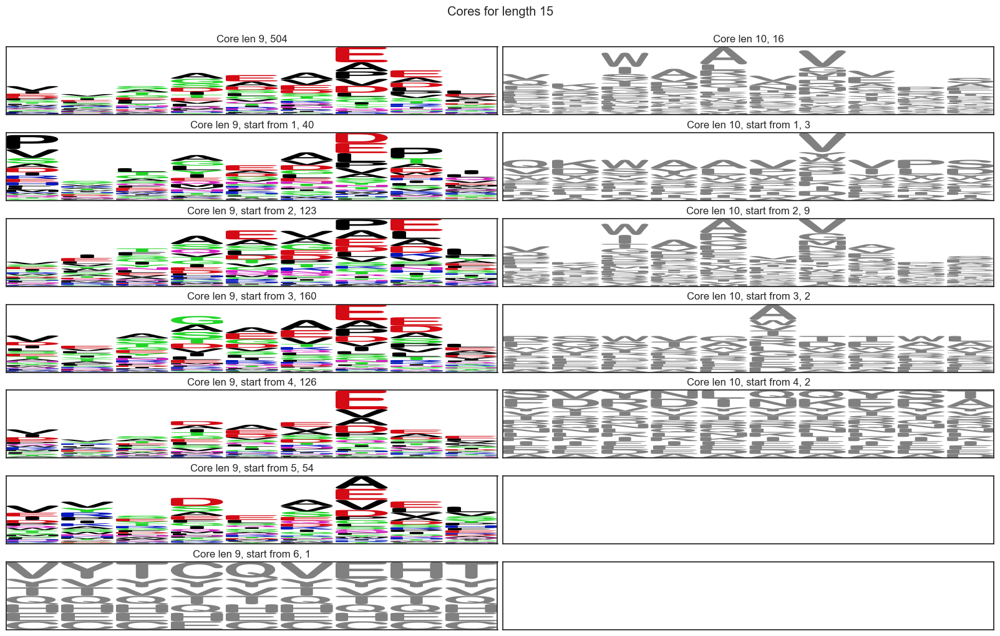

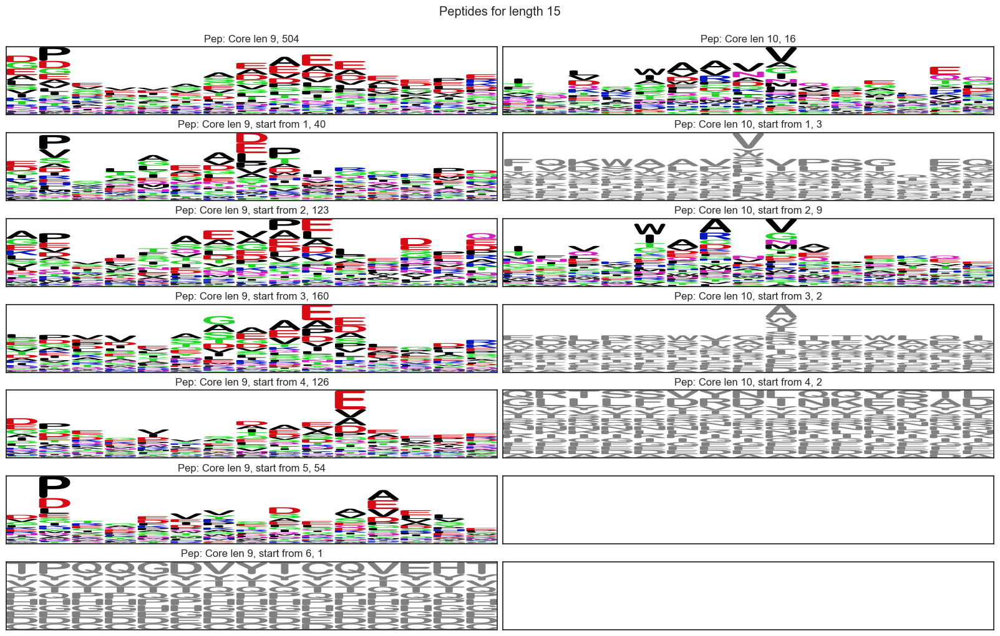

In [96]:
import matplotlib.pyplot as plt
target_peptide_length = 15

target_data = total_df[(total_df.peptide_len == target_peptide_length)]

core_lens = np.array(target_data[(target_data.core_len <= 12) & (target_data.core_len  >= 8 )].core_len.unique())
columns = len(core_lens)
core_shifts = np.array(target_data[target_data.core_start <= 9].core_start.unique())

rows = len(core_shifts) + 1


cores_fig,cores_axes = plt.subplots(ncols=columns, nrows=rows, figsize=(16,10))
peptides_fig, peptides_axes = plt.subplots(ncols=columns, nrows=rows, figsize=(16,10))

#params of axes
for row in range(rows):
    for col in range(columns):
        cores_axes[row, col].get_yaxis().set_visible(False)
        peptides_axes[row, col].get_yaxis().set_visible(False)
        cores_axes[row, col].get_xaxis().set_visible(False)
        peptides_axes[row, col].get_xaxis().set_visible(False)


for col, target_core_len in enumerate(sorted(core_lens)):
    if target_core_len >= 6:
        print(col)
        col_data = target_data[(target_data.core_len == target_core_len)]

        peptides = col_data.index.values
        core_starts = col_data['core_start'].values
        core_ends = col_data['core_end'].values
        cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
        if len(cores) > 0:
            make_logo_for_data(cores, f"Core len {target_core_len}", ax=cores_axes[0, col])
        if len(peptides) > 0:
            make_logo_for_data(peptides, f"Pep: Core len {target_core_len}",ax=peptides_axes[0, col])

        for row, target_core_start in enumerate(sorted(core_shifts),start=1):
            row_data = col_data[(col_data.core_start == target_core_start)]
            peptides = row_data.index.values
            core_starts = row_data['core_start'].values
            core_ends = row_data['core_end'].values
            cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
            if len(cores) > 0:
                make_logo_for_data(cores, f"Core len {target_core_len}, start from {target_core_start}", ax=cores_axes[row, col])
            if len(peptides) > 0:
                make_logo_for_data(peptides, f"Pep: Core len {target_core_len}, start from {target_core_start}",ax=peptides_axes[row, col])

cores_fig.suptitle(f"Cores for length {target_peptide_length}", y=1.01)
peptides_fig.suptitle(f"Peptides for length {target_peptide_length}", y=1.01)
cores_fig.tight_layout(pad=0.5)
peptides_fig.tight_layout(pad=0.5)


# Same but columns are different lengths of peptides

In [106]:
total_df.peptide_len.value_counts()

14    575
15    520
16    456
13    442
17    329
12    277
18    156
11    152
19    107
Name: peptide_len, dtype: int64

In [107]:
import matplotlib.pyplot as plt
# target_peptide_length = 15
def show_shift_subsets(total_df, target_core_len, need_mark_left=True, need_mark_right=True, peptide_to_draw_column='peptide', add_factor=0):
    target_data = total_df[(total_df.core_len == target_core_len)]

    peptide_lengths = np.array(target_data.peptide_len.unique())
    columns = len(peptide_lengths)
    print(f"number of columns {columns}")

    core_shifts = np.array(target_data[target_data.core_start < 9].core_start.unique())

    rows = len(core_shifts) + 1
    print(f"number of rows {rows}")


    cores_fig,cores_axes = plt.subplots(ncols=columns, nrows=rows, figsize=(16,10))
    peptides_fig, peptides_axes = plt.subplots(ncols=columns, nrows=rows, figsize=(16,10))
#params of axes
    for row in range(rows):
        for col in range(columns):
            cores_axes[row, col].get_yaxis().set_visible(False)
            peptides_axes[row, col].get_yaxis().set_visible(False)
            cores_axes[row, col].get_xaxis().set_visible(False)
            peptides_axes[row, col].get_xaxis().set_visible(False)


    for col, target_peptide_length in enumerate(sorted(peptide_lengths)):
        print(col)
        col_data = target_data[(target_data.peptide_len == target_peptide_length)]

        peptides = col_data.index.values
        core_starts = col_data['core_start'].values
        core_ends = col_data['core_end'].values
        cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
        if len(cores) > 0:
            make_logo_for_data(cores, f"Peptide len {target_peptide_length}", ax=cores_axes[0, col])
        if len(peptides) > 0:
            make_logo_for_data(peptides, f"Pep len {target_peptide_length}",ax=peptides_axes[0, col])


        for row, target_core_start in enumerate(sorted(core_shifts),start=1):
            row_data = col_data[(col_data.core_start == target_core_start)]
            peptides = row_data.index.values
            core_starts = row_data['core_start'].values
            core_ends = row_data['core_end'].values
            cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]
            if len(cores) > 0:
                make_logo_for_data(cores, f"Core start from {target_core_start}", ax=cores_axes[row, col])

            len_supossed_to_be = len(row_data)
            row_data = row_data[row_data[peptide_to_draw_column].str.len() == row_data[peptide_to_draw_column].str.len().max()]
            peptides_to_draw = row_data[peptide_to_draw_column].values
            # if len_supossed_to_be != len_that_will_be_used:
                # print(f"found different lengths. Took max. deleted {len_supossed_to_be - len_that_will_be_used} peptides
            mark_left = None
            mark_right = None
            if need_mark_left:
                mark_left = add_factor + target_core_start
            if need_mark_right:
                mark_right = add_factor + target_core_start + target_core_len
            if len(peptides_to_draw) > 1:
                make_logo_for_data(peptides_to_draw, f"Core start {target_core_start}",ax=peptides_axes[row, col], mark_left=mark_left, mark_right=mark_right)

    cores_fig.suptitle(f"Cores for core len {target_core_len} for different peptide len", y=1.01)
    peptides_fig.suptitle(f"Peptides for core len {target_core_len}", y=1.01)
    cores_fig.tight_layout(pad=0.5)
    peptides_fig.tight_layout(pad=0.5)




number of columns 9
number of rows 10
0


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

1


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

2


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

... (5 outputs left out)

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

6


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

KeyboardInterrupt: 

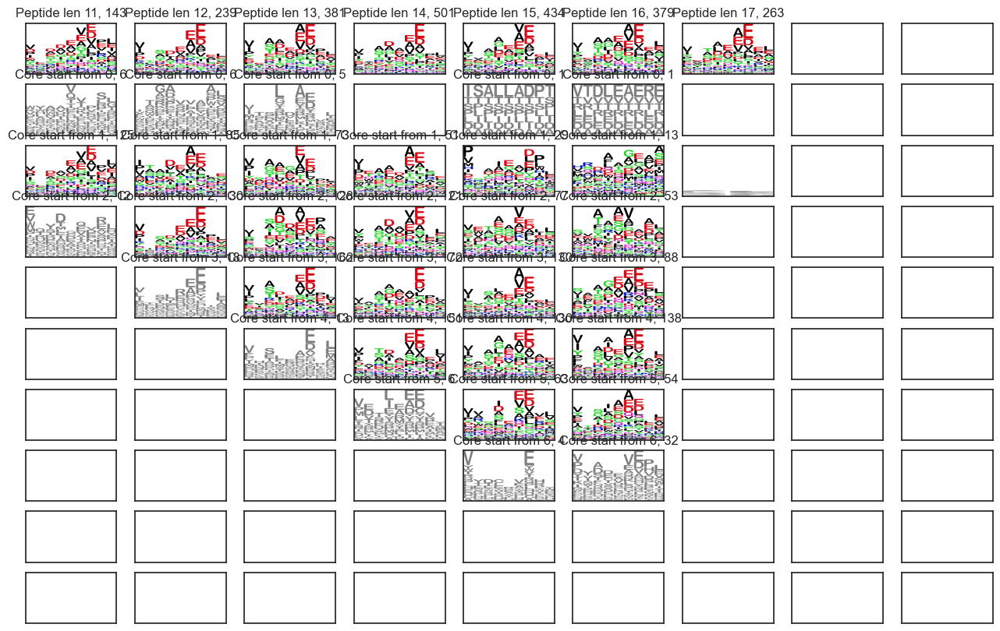

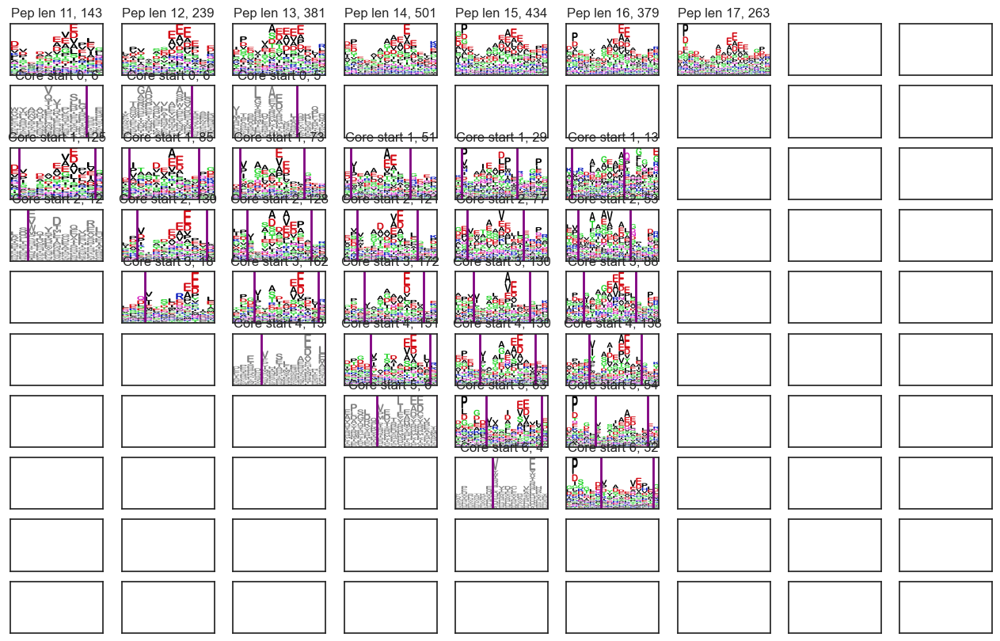

In [108]:
show_shift_subsets(total_df=total_df, target_core_len=9, need_mark_left=True, need_mark_right=True)

In [ ]:
target_data = total_df[(total_df.core_len == target_core_len)]
target_data.sample(1)

In [ ]:
target_data.peptide_len.value_counts()

In [ ]:
target_data.core_start.value_counts()

In [ ]:
target_data.core_start.value_counts()

In [65]:
core_start_value = 2
target_data = total_df[(total_df.core_len == target_core_len) & (total_df.core_start == core_start_value)]

In [66]:
trget_data.peptide_len.value_counts()

15    1141
13     373
14     230
12     224
16      67
17      21
18      21
Name: peptide_len, dtype: int64

C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


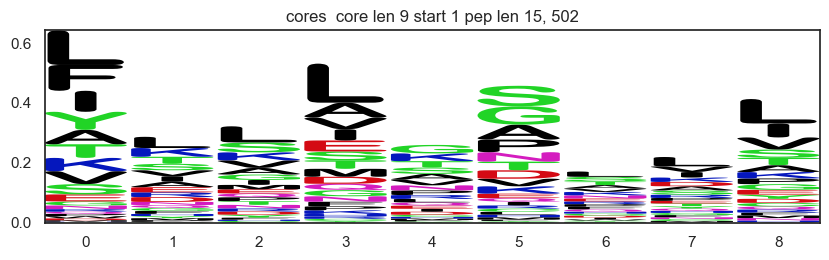

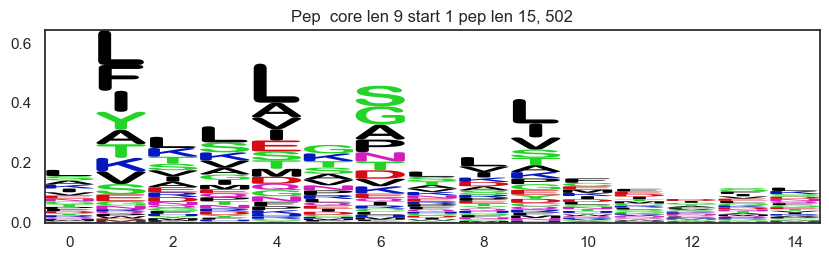

In [77]:
target_peptide_len = 15
target_core_len = 9
core_start = 1
df = restricted_motif(total_df, core_start=core_start, core_len=target_core_len, peptide_len=target_peptide_len,
                 use_peptides=True)


In [78]:
df

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
AAASVPAADKFKTFE,"[2.05, 8.16, 11.31, 13.4, 14.42, 14.42, 15.46,...",AAASVPAADKFKTFE,1,9,9,15,AASVPAADK,"[8.16, 11.31, 13.4, 14.42, 14.42, 15.46, 15.46..."
AASGADGTYDITKLG,"[3.09, 8.22, 8.22, 9.24, 9.24, 12.32, 15.41, 1...",AASGADGTYDITKLG,1,9,9,15,ASGADGTYD,"[8.22, 8.22, 9.24, 9.24, 12.32, 15.41, 15.41, ..."
AATAAAAAAVDRGDP,"[0.0, 10.24, 14.41, 15.43, 15.43, 15.43, 15.43...",AATAAAAAAVDRGDP,1,9,9,15,ATAAAAAAV,"[10.24, 14.41, 15.43, 15.43, 15.43, 15.43, 15...."
AAVGATPEAKFDSFV,"[4.16, 13.3, 13.3, 13.3, 14.34, 15.36, 15.36, ...",AAVGATPEAKFDSFV,1,9,9,15,AVGATPEAK,"[13.3, 13.3, 13.3, 14.34, 15.36, 15.36, 15.36,..."
AAVKAGAALLDGGNM,"[0.0, 11.11, 13.2, 14.22, 14.22, 14.22, 15.25,...",AAVKAGAALLDGGNM,1,9,9,15,AVKAGAALL,"[11.11, 13.2, 14.22, 14.22, 14.22, 15.25, 15.2..."
...,...,...,...,...,...,...,...,...
YLSLLSACNKIKGKK,"[4.15, 9.34, 11.4, 11.4, 12.44, 14.59, 15.59, ...",YLSLLSACNKIKGKK,1,9,9,15,LSLLSACNK,"[9.34, 11.4, 11.4, 12.44, 14.59, 15.59, 15.59,..."
YSEESPTEYTCISPN,"[4.12, 11.2, 12.23, 12.23, 13.28, 14.3, 15.32,...",YSEESPTEYTCISPN,1,9,9,15,SEESPTEYT,"[11.2, 12.23, 12.23, 13.28, 14.3, 15.32, 15.32..."
YSQLMCQPILLLDQV,"[4.1, 8.23, 8.23, 12.28, 12.28, 12.28, 15.36, ...",YSQLMCQPILLLDQV,1,9,9,15,SQLMCQPIL,"[8.23, 8.23, 12.28, 12.28, 12.28, 15.36, 15.36..."
YTQCIKGSPEFDWIL,"[2.1, 9.22, 10.23, 11.24, 13.28, 14.32, 15.32,...",YTQCIKGSPEFDWIL,1,9,9,15,TQCIKGSPE,"[9.22, 10.23, 11.24, 13.28, 14.32, 15.32, 15.3..."


In [74]:
len(total_df)

12062

## How many n-mer motifs we will find with different thesholds

In [34]:
from tqdm import tqdm
lengths_to_try = [6, 7,8,9, 10, 11, 12, 13]
length_to_number_of_points = defaultdict(list)
for threshold in tqdm(np.linspace(start=1, stop=len(per_name_models), num=50)):
    total_df['core_start'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[0] if len(x) > 0 else 0)

    total_df['core_end'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[-1] if len(x)> 0 else 1)
    total_df['core_len'] = total_df['core_end'] - total_df['core_start'] + 1
    total_df['peptide_len'] = total_df.index.str.len()
    total_df['core_peptide'] =total_df.apply(lambda row: row.name[row['core_start']:row['core_end'] + 1], axis=1)
    total_df = total_df[~total_df.index.duplicated(keep='first')]
    total_df['simplified_path'] = total_df['simplified_path'].apply(lambda x: np.round(x.astype(float),2))
    total_df['core_path'] = total_df.apply(lambda row: row['simplified_path'][row['core_start']:row['core_end'] + 1] , axis=1)

    split_result = dict(total_df.core_len.value_counts())
    for target_length in lengths_to_try:
        value = 0
        if target_length in split_result:
            value = split_result[target_length]
        length_to_number_of_points[f"len {target_length}"].append(value)




100%|██████████| 50/50 [00:36<00:00,  1.38it/s]


In [35]:
df = pd.DataFrame(length_to_number_of_points, index=np.linspace(start=1, stop=len(per_name_models), num=50))
df['threshold'] = df.index.values
df

,len 6,len 7,len 8,len 9,len 10,len 11,len 12,len 13,threshold
1.000000,0,0,0,102,7154,1273,747,625,1.000000
1.285714,0,0,0,423,8129,715,457,357,1.285714
1.571429,0,0,0,423,8129,715,457,357,1.571429
1.857143,0,0,0,423,8129,715,457,357,1.857143
2.142857,0,0,0,7731,1614,396,288,149,2.142857
2.428571,0,0,0,7736,1617,395,287,144,2.428571
2.714286,0,0,0,7736,1617,395,287,144,2.714286
3.000000,0,0,0,7890,1463,395,287,144,3.000000
3.285714,0,0,0,8915,713,286,203,88,3.285714
3.571429,0,0,0,8915,713,286,204,87,3.571429


In [36]:
df = df.melt(value_vars=[f"len {length}" for length in lengths_to_try], id_vars='threshold', var_name='motif_length')
df['label'] = df['value'].values
df

,threshold,motif_length,value,label
0,1.000000,len 6,0,0
1,1.285714,len 6,0,0
2,1.571429,len 6,0,0
3,1.857143,len 6,0,0
4,2.142857,len 6,0,0
...,...,...,...,...
395,13.857143,len 13,0,0
396,14.142857,len 13,0,0
397,14.428571,len 13,0,0
398,14.714286,len 13,0,0


In [37]:
import seaborn as sns

In [38]:
df.loc[df['value'].argmax()]

threshold       7.571429
motif_length       len 9
value              10232
label              10232
Name: 173, dtype: object

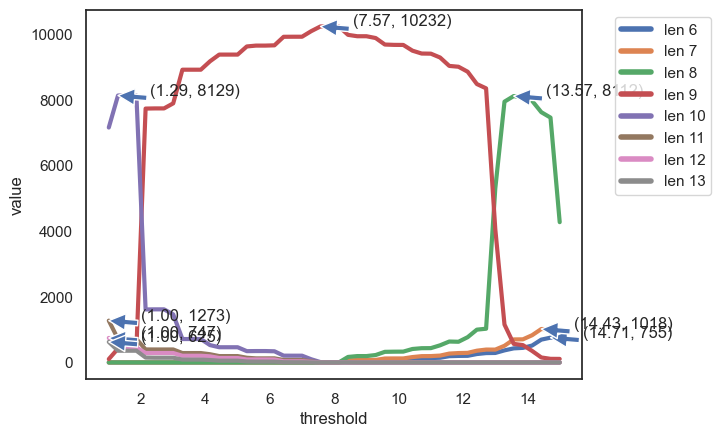

In [39]:
import matplotlib.pyplot as plt
sns.set_theme(style="white")

ax = sns.lineplot(data=df, x='threshold', y='value', hue='motif_length', markers=False,linewidth=3)

for target_length in lengths_to_try:
    temp_df = df[df.motif_length == f'len {target_length}'].copy()
    max_x = temp_df.loc[temp_df['value'].idxmax()]['threshold']
    max_y = temp_df['value'].max()
    ax.annotate(f'({max_x:.2f}, {max_y})', xy=(max_x, max_y),  xytext=(max_x + 1, max_y+10),  arrowprops=dict())
# plt.legend(bbox_to_anchor=(1.02, 0.15), loc='upper left', borderaxespad=0)
# ax.text(max_x,max_y,f'{max_y}')
# sns.move_legend(ax, "upper left", bbox_to_anchor=(.55, .45), frameon=False)
# get the legend object
leg = ax.legend()
# change the line width for the legend
for line in leg.get_lines():
    line.set_linewidth(4.0)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.05, 1), markerscale=10)

# ax.text(max_x,max_y,f'{max_y}')

In [312]:
path  = [item[1].name for item in model.viterbi('SIAAVEMEHFLPL')[1]]
path

['grouped_model-start',
 's009',
 's009',
 's009',
 's009',
 's007',
 's000',
 's001',
 's002',
 's003',
 's004',
 's005',
 's006',
 's008',
 'grouped_model-end']

In [493]:
[per_state_information[state] for state in path[1:-1]]

[0.3065507797068359,
 0.3065507797068359,
 0.3065507797068359,
 0.3065507797068359,
 1.216452145779746,
 1.8793342691024757,
 2.011791918974574,
 2.5335050925180753,
 2.497233232183504,
 2.0596859054675463,
 2.5627528678463927,
 2.2960962978628086,
 1.0239079381842002]

# Check if we will see something interesting with padded peptides

In [30]:
TARGET_ALLELE = ALLELES[0]

In [31]:
IEDB_DATA_PATH = DATA_PATH_BASE + '/Binding data/IEDB/mhc_ligand_full_single_file/mhc_ligand_full.csv'
UNIPROT_DATA_PATH = DATA_PATH_BASE + '/uniprot_data/'

In [32]:

iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0, 1])

C:\Users\denkl\AppData\Local\Temp\ipykernel_19692\585813042.py:1: DtypeWarning: Columns (5,14,23,24,25,26,29,30,31,32,33,34,35,36,37,38,41,42,43,44,45,46,47,48,49,50,53,54,55,56,57,58,59,60,61,62,63,64,65,68,69,70,71,72,73,74,75,76,77,78,81,84,89,90,91,92,93,94,97,99) have mixed types. Specify dtype option on import or set low_memory=False.
  iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0, 1])


In [33]:
def tuple_to_last_elem(column):
    return column[-1]
def filter_iedb_dataset_with_protein(iedb_df, include_qualitative=True, include_mass_spec=True):
    QUALITATIVE_TO_AFFINITY_AND_INEQUALITY = {
        "Negative": (5000.0, ">"),
        "Positive": (500.0, "<"),  # used for mass-spec hits
        "Positive-High": (100.0, "<"),
        "Positive-Intermediate": (1000.0, "<"),
        "Positive-Low": (5000.0, "<"),
    }
    QUALITATIVE_TO_AFFINITY = dict(
        (key, value[0]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    QUALITATIVE_TO_INEQUALITY = dict(
        (key, value[1]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())



    print("Loaded iedb data: %s" % str(iedb_df.shape))
    filtered_df = iedb_df.copy()
    filtered_df = filtered_df[filtered_df[('Epitope', 'Object Type')] == "Linear peptide"]
    print("Linear peptides only, remaining: %d" % len(filtered_df))

    ## Clear bad data
    print("Subselecting to valid peptides (dropping peptides with PTMs). Starting with: %d" % len(filtered_df))
    filtered_df[('Epitope', 'Description')] = filtered_df[('Epitope', 'Description')].str.strip()
    filtered_df = filtered_df.loc[
        iedb_df[('Epitope', 'Description')].str.match("^[ACDEFGHIKLMNPQRSTVWY]+$")
    ]
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))


    #     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("\+")]
    #     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("X")]
    #     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("B")]
    #     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("Z")]

    filtered_df = filtered_df[[
        ('Epitope', 'Object Type'),
        ('Epitope', 'Description'),
        ('Epitope', 'Parent Species'),
        ('Assay', 'Units'),
        ('Assay', 'Qualitative Measure'),
        ('Assay', 'Quantitative measurement'),
        ('Assay', 'Measurement Inequality'),
        ('MHC', 'Allele Name'),
        ('MHC', 'Allele IRI'),
        ('MHC', 'MHC allele class'),
        ('Assay', 'Assay Group'),
        ('Assay', 'Method/Technique'),
        ('Epitope', 'Parent Protein IRI'),
        ('Epitope', 'Starting Position'),
        ('Epitope', 'Ending Position')
    ]]
    print("Subselecting assay groups as in Sarkizova. Starting with: %d" % len(filtered_df))

    assay_type1 = (filtered_df[('Assay', 'Assay Group')] == 'half maximal effective concentration (EC50)') & \
                                              (filtered_df[('Assay', 'Method/Technique')] == 'purified MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type1]

    assay_type2 = (filtered_df[('Assay', 'Assay Group')] =='dissociation constant KD') & \
                                                  (filtered_df[('Assay', 'Method/Technique')] == 'purified MHC/direct/radioactivity')
    filtered_df = filtered_df[~assay_type2]
    assay_type3 = (filtered_df[('Assay', 'Assay Group')] == 'half maximal effective concentration (EC50)') & \
                                                  (filtered_df[('Assay', 'Method/Technique')] == 'cellular MHC/direct/fluorescence')

    filtered_df = filtered_df[~assay_type3]
    filtered_df.columns = filtered_df.columns.map(tuple_to_last_elem)
    print("Now: %d" % len(filtered_df))


    quantitative = filtered_df.loc[filtered_df["Units"] == "nM"].copy()
    quantitative["measurement_type"] = "quantitative"
    quantitative = quantitative.rename(columns={"Measurement Inequality":"measurement_inequality"})
    quantitative['measurement_inequality'] = quantitative['measurement_inequality'].fillna("=").map(lambda s: {">=": ">", "<=": "<"}.get(s, s))
    print("Quantitative measurements: %d" % len(quantitative))
    # Ilya: remove quantitative measurement with no measurement values
    print("Dropping quantitative measurements with no measurement value")
    quantitative.dropna(subset = ["Quantitative measurement"], inplace=True)
    print("Quantitative measurements: %d" % len(quantitative))

    qualitative = filtered_df.loc[filtered_df["Units"] != "nM"].copy()
    qualitative["measurement_type"] = "qualitative"
    print("Qualitative measurements: %d" % len(qualitative))
    if not include_mass_spec:
        qualitative = qualitative.loc[
            (~qualitative["Method/Technique"].str.contains("mass spec"))
        ].copy()

    qualitative["Quantitative measurement"] = (
        qualitative["Qualitative Measure"].map(QUALITATIVE_TO_AFFINITY))
    qualitative = qualitative.drop(columns=['Measurement Inequality'])
    qualitative["measurement_inequality"] = (qualitative["Qualitative Measure"].map(QUALITATIVE_TO_INEQUALITY))

    print("Qualitative measurements (possibly after dropping MS): %d" % (
        len(qualitative)))

    filtered_df = pd.concat(
        (
                ([quantitative]) +
                ([qualitative] if include_qualitative else [])),
        ignore_index=True)
    print("Now: %d" % len(filtered_df))

    ## Mark binders
    binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
    non_binder_list = ['Negative']
    filtered_df.loc[filtered_df['Quantitative measurement'] <= 500, 'binder'] = 1
    filtered_df.loc[filtered_df['Quantitative measurement'] > 500, 'binder'] = 0
    #
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(binder_list),'binder'] = 1
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(non_binder_list),'binder'] = 0

    filtered_df.binder = filtered_df.binder.astype(int)
    filtered_df = filtered_df.drop(columns=[
        'Qualitative Measure',
        'Units',
        'Object Type',
        'Allele IRI'
    ])
    print(f"Filter out without potein")
    filtered_df[filtered_df['Parent Protein IRI'].notnull()]
    filtered_df = filtered_df.rename(columns={"Allele Name":"allele",
                                              "Description":"peptide",
                                              "Quantitative measurement":"measurement_value",
                                              "Parent Protein IRI":"protein_value",
                                              "Starting Position":"peptide_start",
                                              "Ending Position": "peptide_end"})
    print(f"Not it is %d values" % len(filtered_df))

    filtered_df['length'] = filtered_df['peptide'].str.len()

    #filtered_df['allele'] = filtered_df['original_allele'].map(parse).to_string()

    print("Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality', 'measurement_type', binder, protein_value, start, end). Starting with: %d" % len(filtered_df))

    filtered_df = filtered_df.drop_duplicates([
        'peptide',
        'allele',
        'length',
        'measurement_value',
        'measurement_inequality',
        'measurement_type',
        'binder',
        'protein_value',
       'peptide_start',
       'peptide_end']).reset_index(drop=True)
    print("Now: %d" % len(filtered_df))


    print("Allele_distribution")
    print(filtered_df['allele'].value_counts()[:30])



    assert 'peptide' in filtered_df.columns
    assert 'allele' in filtered_df.columns
    assert 'length' in filtered_df.columns
    assert 'binder' in filtered_df.columns
    assert 'protein_value' in filtered_df.columns
    assert 'peptide_start' in filtered_df.columns
    return filtered_df

In [34]:
iedb_df = filter_iedb_dataset_with_protein(iedb_df)


Loaded iedb data: (3235984, 100)
Linear peptides only, remaining: 3235229
Subselecting to valid peptides (dropping peptides with PTMs). Starting with: 3235229
Now: 3104634
Subselecting assay groups as in Sarkizova. Starting with: 3104634
Now: 3103070
Quantitative measurements: 235469
Dropping quantitative measurements with no measurement value
Quantitative measurements: 235321
Qualitative measurements: 2867601
Qualitative measurements (possibly after dropping MS): 2867601
Now: 3102922
Filter out without potein
Not it is 3102922 values
Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality', 'measurement_type', binder, protein_value, start, end). Starting with: 3102922
Now: 1689875
Allele_distribution
HLA class I                  334186
HLA class II                 143459
HLA-B*27:05                   94780
HLA-A*02:01                   68610
HLA-B*07:02                   32385
HLA-DR                        31141
HLA-B*57:01                   26965
HLA-A*01:0

In [35]:
binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
non_binder_list = ['Negative']

In [36]:
iedb_df = iedb_df[iedb_df['allele'] == TARGET_ALLELE]
iedb_df = iedb_df[iedb_df['binder'] == 1]


In [37]:
iedb_df

,peptide,Parent Species,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_value,peptide_start,peptide_end,measurement_type,binder,length
67,PHHTALRQAILCWGELMTLA,Hepatitis B virus,70.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R61,50.0,69.0,quantitative,1,20
76,AGFFLLTRILTIPQS,Hepatitis B virus,1.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,180.0,194.0,quantitative,1,15
86,LVPFVQWFVGLSPTV,Hepatitis B virus,385.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,339.0,353.0,quantitative,1,15
106,RHYLHTLWKAGILYK,Hepatitis B virus,17.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,145.0,159.0,quantitative,1,15
126,LQSLTNLLSSNLSWL,Hepatitis B virus,2.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,412.0,426.0,quantitative,1,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1614159,IWLGFIAGLIAIVMV,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,1216.0,1230.0,qualitative,1,15
1614162,LAFVVFLLVTLAILT,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC4,21.0,35.0,qualitative,1,15
1614165,MKIILFLALITLATC,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC7,1.0,15.0,qualitative,1,15
1614168,TQDLFLPFFSNVTWF,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,51.0,65.0,qualitative,1,15


In [38]:
unique_protein_ids = set(iedb_df['protein_value'].str.rsplit('/', 1, expand=True)[1].unique())
iedb_df['protein_id'] = iedb_df['protein_value'].str.rsplit('/', 1, expand=True)[1]

C:\Users\denkl\AppData\Local\Temp\ipykernel_19692\1417621295.py:1: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  unique_protein_ids = set(iedb_df['protein_value'].str.rsplit('/', 1, expand=True)[1].unique())
C:\Users\denkl\AppData\Local\Temp\ipykernel_19692\1417621295.py:2: FutureWarning: In a future version of pandas all arguments of StringMethods.rsplit except for the argument 'pat' will be keyword-only.
  iedb_df['protein_id'] = iedb_df['protein_value'].str.rsplit('/', 1, expand=True)[1]


In [39]:
len(unique_protein_ids)

2858

In [40]:
from Bio.SeqIO.FastaIO import SimpleFastaParser
uniprot_file = f'{UNIPROT_DATA_PATH}uniprot_sprot.fasta'
def read_uniprot_file_to_dict_simple(file_path, protein_ids):
    result_dict = dict()
    with open(file_path) as handle:
        for record in SimpleFastaParser(handle):
            uniprot_id = record[0].split('|',2)[1]
            if uniprot_id in protein_ids:
                result_dict[uniprot_id] = str(record[1])
                if len(result_dict) == len(protein_ids):
                    return result_dict
    return result_dict


In [41]:
uniprot_dict = read_uniprot_file_to_dict_simple(uniprot_file, unique_protein_ids)
diff = np.setdiff1d(list(unique_protein_ids), np.array(list(uniprot_dict.keys())))
print(f"found {len(uniprot_dict)} not found {len(diff)}")


found 2350 not found 508


In [42]:
# add protein sequences
print(f"starting with {len(iedb_df)}")
iedb_df['protein'] = iedb_df['protein_id'].map(uniprot_dict)
print(f"CHECK: now is {len(iedb_df)}")

starting with 15499
CHECK: now is 15499


In [496]:
iedb_df

,peptide,Parent Species,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_value,peptide_start,peptide_end,measurement_type,binder,length,protein_id,protein
67,PHHTALRQAILCWGELMTLA,Hepatitis B virus,70.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R61,50.0,69.0,quantitative,1,20,Q76R61,MDIDPYKEFGASVELLSFLPSDFFPSIRDLLDTASALYREALESPE...
76,AGFFLLTRILTIPQS,Hepatitis B virus,1.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,180.0,194.0,quantitative,1,15,Q76R62,MGGWSSKPRQGMGTNLSVPNPLGFFPDHQLDPAFGANSNNPDWDFN...
86,LVPFVQWFVGLSPTV,Hepatitis B virus,385.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,339.0,353.0,quantitative,1,15,Q76R62,MGGWSSKPRQGMGTNLSVPNPLGFFPDHQLDPAFGANSNNPDWDFN...
106,RHYLHTLWKAGILYK,Hepatitis B virus,17.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,145.0,159.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
126,LQSLTNLLSSNLSWL,Hepatitis B virus,2.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,412.0,426.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1614159,IWLGFIAGLIAIVMV,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,1216.0,1230.0,qualitative,1,15,P0DTC2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...
1614162,LAFVVFLLVTLAILT,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC4,21.0,35.0,qualitative,1,15,P0DTC4,MYSFVSEETGTLIVNSVLLFLAFVVFLLVTLAILTALRLCAYCCNI...
1614165,MKIILFLALITLATC,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC7,1.0,15.0,qualitative,1,15,P0DTC7,MKIILFLALITLATCELYHYQECVRGTTVLLKEPCSSGTYEGNSPF...
1614168,TQDLFLPFFSNVTWF,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,51.0,65.0,qualitative,1,15,P0DTC2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...


In [43]:
proteins_not_found_len = len(iedb_df[iedb_df['protein'].isnull()])
print(f"proteins were not assigned for {proteins_not_found_len} of {len(iedb_df)}")
iedb_df = iedb_df[iedb_df['protein_id'].isin(uniprot_dict)]
print(f"Removed {proteins_not_found_len}: \t sequences (protein was not found in current uniprot_dict)")

no_start_pos_count = len(iedb_df[iedb_df['peptide_start'].isnull()])
iedb_df = iedb_df[~iedb_df['peptide_start'].isnull()]
print(f"Removed {no_start_pos_count}: \t no start position")


dupl_rows = len(iedb_df)
iedb_df = iedb_df.drop_duplicates(['peptide'], keep='last')
unique_rows = len(iedb_df)
print(f"Removed {dupl_rows - unique_rows}: \t duplicate peptide rows")
iedb_df = iedb_df.set_index('peptide')




proteins were not assigned for 2553 of 15499
Removed 2553: 	 sequences (protein was not found in current uniprot_dict)
Removed 1702: 	 no start position
Removed 616: 	 duplicate peptide rows


In [498]:
iedb_df

,Parent Species,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_value,peptide_start,peptide_end,measurement_type,binder,length,protein_id,protein
peptide,,,,,,,,,,,,,,,
PHHTALRQAILCWGELMTLA,Hepatitis B virus,70.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R61,50.0,69.0,quantitative,1,20,Q76R61,MDIDPYKEFGASVELLSFLPSDFFPSIRDLLDTASALYREALESPE...
AGFFLLTRILTIPQS,Hepatitis B virus,1.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,180.0,194.0,quantitative,1,15,Q76R62,MGGWSSKPRQGMGTNLSVPNPLGFFPDHQLDPAFGANSNNPDWDFN...
RHYLHTLWKAGILYK,Hepatitis B virus,17.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,145.0,159.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
LQSLTNLLSSNLSWL,Hepatitis B virus,2.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,412.0,426.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
SSNLSWLSLDVSAAF,Hepatitis B virus,38.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,420.0,434.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IWLGFIAGLIAIVMV,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,1216.0,1230.0,qualitative,1,15,P0DTC2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...
LAFVVFLLVTLAILT,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC4,21.0,35.0,qualitative,1,15,P0DTC4,MYSFVSEETGTLIVNSVLLFLAFVVFLLVTLAILTALRLCAYCCNI...
MKIILFLALITLATC,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC7,1.0,15.0,qualitative,1,15,P0DTC7,MKIILFLALITLATCELYHYQECVRGTTVLLKEPCSSGTYEGNSPF...


In [44]:
target_peptides = iedb_df[iedb_df.length.isin([12,13,14,15,16,17,18])].index.values

In [45]:
len(target_peptides)

9170

In [46]:
total_df, _ = calculate_model_core_guesses(target_peptides, per_name_models, None)

Model 0_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 9170/9170 [00:00<00:00, 57825.51it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 9170 


100%|██████████| 9170/9170 [00:00<00:00, 15999.04it/s]


Model 1_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 9170/9170 [00:00<00:00, 50289.64it/s]


... (50 outputs left out)

Model 14_run-12-13-14-15-16-17-18-7-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 9170/9170 [00:00<00:00, 53617.36it/s]


Subselect unique paths (if unique path argument passed)..
	Unique paths: 9170 


100%|██████████| 9170/9170 [00:00<00:00, 16204.42it/s]


In [47]:
total_df['core_start'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[0] if len(x) > 0 else 0)

total_df['core_end'] = total_df['simplified_path'].apply(lambda x: np.where(np.array(x) > threshold)[0]).apply(lambda x: x[-1] if len(x)> 0 else 1)
total_df['core_len'] = total_df['core_end'] - total_df['core_start'] + 1
total_df['peptide_len'] = total_df.index.str.len()
total_df['core_peptide'] =total_df.apply(lambda row: row.name[row['core_start']:row['core_end'] + 1], axis=1)
total_df = total_df[~total_df.index.duplicated(keep='first')]
total_df['simplified_path'] = total_df['simplified_path'].apply(lambda x: np.round(x.astype(float),2))
total_df['core_path'] = total_df.apply(lambda row: row['simplified_path'][row['core_start']:row['core_end'] + 1] , axis=1)


In [505]:
threshold

7.86

In [506]:
total_df[['simplified_path', 'core_peptide', 'core_start' ]]

,simplified_path,core_peptide,core_start
AGFFLLTRILTIPQS,"[2.02, 5.05, 15.25, 15.25, 15.25, 15.25, 15.25...",FFLLTRILT,2
RHYLHTLWKAGILYK,"[0.0, 4.14, 5.19, 15.52, 15.52, 15.52, 15.52, ...",LHTLWKAGI,3
LQSLTNLLSSNLSWL,"[0.0, 2.02, 5.08, 15.28, 15.28, 15.28, 15.28, ...",LTNLLSSNL,3
SSNLSWLSLDVSAAF,"[0.0, 0.0, 0.0, 2.05, 5.08, 15.08, 15.08, 15.0...",WLSLDVSAA,5
LHLYSHPIILGFRKI,"[0.0, 2.09, 10.58, 15.91, 15.91, 15.91, 15.91,...",LYSHPIILG,2
...,...,...,...
IWLGFIAGLIAIVMV,"[0.0, 3.13, 3.13, 5.15, 5.15, 15.62, 15.62, 15...",IAGLIAIVM,5
LAFVVFLLVTLAILT,"[0.0, 2.06, 2.06, 5.21, 15.51, 15.51, 15.51, 1...",VFLLVTLAI,4
MKIILFLALITLATC,"[0.0, 0.0, 0.0, 2.06, 5.09, 15.15, 15.15, 15.1...",FLALITLAT,5
TQDLFLPFFSNVTWF,"[0.0, 0.0, 2.01, 5.01, 15.01, 15.01, 15.01, 15...",FLPFFSNVT,4


In [507]:
iedb_df

,Parent Species,measurement_value,measurement_inequality,allele,MHC allele class,Assay Group,Method/Technique,protein_value,peptide_start,peptide_end,measurement_type,binder,length,protein_id,protein
peptide,,,,,,,,,,,,,,,
PHHTALRQAILCWGELMTLA,Hepatitis B virus,70.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R61,50.0,69.0,quantitative,1,20,Q76R61,MDIDPYKEFGASVELLSFLPSDFFPSIRDLLDTASALYREALESPE...
AGFFLLTRILTIPQS,Hepatitis B virus,1.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q76R62,180.0,194.0,quantitative,1,15,Q76R62,MGGWSSKPRQGMGTNLSVPNPLGFFPDHQLDPAFGANSNNPDWDFN...
RHYLHTLWKAGILYK,Hepatitis B virus,17.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,145.0,159.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
LQSLTNLLSSNLSWL,Hepatitis B virus,2.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,412.0,426.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
SSNLSWLSLDVSAAF,Hepatitis B virus,38.0,=,HLA-DRB1*01:01,II,half maximal inhibitory concentration (IC50),purified MHC/competitive/radioactivity,http://www.uniprot.org/uniprot/Q69028,420.0,434.0,quantitative,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IWLGFIAGLIAIVMV,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC2,1216.0,1230.0,qualitative,1,15,P0DTC2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...
LAFVVFLLVTLAILT,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC4,21.0,35.0,qualitative,1,15,P0DTC4,MYSFVSEETGTLIVNSVLLFLAFVVFLLVTLAILTALRLCAYCCNI...
MKIILFLALITLATC,Severe acute respiratory syndrome-related coro...,500.0,<,HLA-DRB1*01:01,II,qualitative binding,purified MHC/competitive/fluorescence,http://www.uniprot.org/uniprot/P0DTC7,1.0,15.0,qualitative,1,15,P0DTC7,MKIILFLALITLATCELYHYQECVRGTTVLLKEPCSSGTYEGNSPF...


In [508]:
total_df

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path
AGFFLLTRILTIPQS,"[2.02, 5.05, 15.25, 15.25, 15.25, 15.25, 15.25...",AGFFLLTRILTIPQS,2,10,9,15,FFLLTRILT,"[15.25, 15.25, 15.25, 15.25, 15.25, 15.25, 15...."
RHYLHTLWKAGILYK,"[0.0, 4.14, 5.19, 15.52, 15.52, 15.52, 15.52, ...",RHYLHTLWKAGILYK,3,11,9,15,LHTLWKAGI,"[15.52, 15.52, 15.52, 15.52, 15.52, 15.52, 15...."
LQSLTNLLSSNLSWL,"[0.0, 2.02, 5.08, 15.28, 15.28, 15.28, 15.28, ...",LQSLTNLLSSNLSWL,3,11,9,15,LTNLLSSNL,"[15.28, 15.28, 15.28, 15.28, 15.28, 15.28, 15...."
SSNLSWLSLDVSAAF,"[0.0, 0.0, 0.0, 2.05, 5.08, 15.08, 15.08, 15.0...",SSNLSWLSLDVSAAF,5,13,9,15,WLSLDVSAA,"[15.08, 15.08, 15.08, 15.08, 15.08, 15.08, 15...."
LHLYSHPIILGFRKI,"[0.0, 2.09, 10.58, 15.91, 15.91, 15.91, 15.91,...",LHLYSHPIILGFRKI,2,10,9,15,LYSHPIILG,"[10.58, 15.91, 15.91, 15.91, 15.91, 15.91, 15...."
...,...,...,...,...,...,...,...,...
IWLGFIAGLIAIVMV,"[0.0, 3.13, 3.13, 5.15, 5.15, 15.62, 15.62, 15...",IWLGFIAGLIAIVMV,5,13,9,15,IAGLIAIVM,"[15.62, 15.62, 15.62, 15.62, 15.62, 12.49, 12...."
LAFVVFLLVTLAILT,"[0.0, 2.06, 2.06, 5.21, 15.51, 15.51, 15.51, 1...",LAFVVFLLVTLAILT,4,12,9,15,VFLLVTLAI,"[15.51, 15.51, 15.51, 15.51, 15.51, 15.51, 13...."
MKIILFLALITLATC,"[0.0, 0.0, 0.0, 2.06, 5.09, 15.15, 15.15, 15.1...",MKIILFLALITLATC,5,13,9,15,FLALITLAT,"[15.15, 15.15, 15.15, 15.15, 15.15, 15.15, 15...."
TQDLFLPFFSNVTWF,"[0.0, 0.0, 2.01, 5.01, 15.01, 15.01, 15.01, 15...",TQDLFLPFFSNVTWF,4,12,9,15,FLPFFSNVT,"[15.01, 15.01, 15.01, 15.01, 15.01, 15.01, 15...."


In [49]:
## Join performed here
total_df = total_df.join(iedb_df)

In [510]:
total_df[['simplified_path', 'core_peptide', 'core_start', 'protein', 'peptide_start', 'peptide_end']].sample(frac=1.0)

,simplified_path,core_peptide,core_start,protein,peptide_start,peptide_end
HPSQPFYILKPQMPWE,"[0.0, 0.0, 0.0, 2.0, 5.0, 15.0, 15.0, 15.0, 15...",FYILKPQMP,5,MIHTNLKRKFSCFVLVFLLFAIICVWKKGSDYEALTLQAKVFQMPK...,285.0,300.0
ETKFLTNKLLLFADI,"[0.0, 12.02, 15.13, 15.13, 15.13, 15.13, 15.13...",TKFLTNKLL,1,MESLVLGVNEKTHVQLSLPVLQVRDVLVRGFGDSVEEALSEAREHL...,1221.0,1235.0
AKTFDQLTPEESKE,"[0.0, 2.0, 5.0, 15.0, 15.0, 15.0, 15.0, 15.0, ...",FDQLTPEES,3,MDLRQFLMCLSLCTAFALSKPTEKKDRVHHEPQLSDKVHNDAQSFD...,58.0,71.0
SPGLKVPVFYAL,"[0.0, 5.16, 15.26, 15.26, 15.26, 15.26, 15.26,...",GLKVPVFYA,2,MRMCTPIRGLLMALAVMFGTAMAFAPIPRITWEHREVHLVQFHEPD...,301.0,312.0
TVQYRTQGAVEAAKVG,"[0.0, 2.0, 5.0, 15.0, 15.0, 15.0, 15.0, 15.0, ...",YRTQGAVEA,3,MKFLIFAFFGGVHLLSLCSGKAICKNGISKRTFEEIKEEIASCGDV...,183.0,198.0
...,...,...,...,...,...,...
EPDAFWEALGGKTAYRT,"[0.0, 0.0, 0.0, 2.0, 5.01, 15.01, 15.01, 15.01...",WEALGGKTA,5,MAPYRSSLLCALLLLALCALSPSHAATTSRGRAQERAPQSRVSEAR...,635.0,651.0
SAKPVSQMRMATPLLMRP,"[0.0, 0.0, 0.0, 0.0, 0.0, 2.02, 5.02, 15.02, 1...",MRMATPLLM,7,MDDQRDLISNHEQLPILGNRPREPERCSRGALYTGVSVLVALLLAG...,83.0,100.0
EQQWNFAGIEAAASA,"[0.0, 0.0, 0.0, 2.05, 5.13, 15.26, 15.26, 15.2...",FAGIEAAAS,5,MTEQQWNFAGIEAAASAIQGNVTSIHSLLDEGKQSLTKLAAAWGGS...,3.0,17.0
EYLVVHLKGSLVKDSQ,"[0.0, 2.0, 5.0, 15.0, 15.0, 15.0, 15.0, 15.0, ...",VVHLKGSLV,3,MAKGFYISKSLGILGILLGVAAVCTIIALSVVYSQEKNKNANSSPV...,160.0,175.0


In [50]:
# Add padded peptide
pad_value = 4
total_df['new_peptide'] = total_df.apply(lambda row: row['protein'][int(row['peptide_start']) - 1 -pad_value:int(row['peptide_end']) + pad_value], axis=1)
total_df['new_peptide_len'] = total_df.new_peptide.str.len()

In [51]:
df = total_df
target_core_len = 9
df = df[df['core_len'] == target_core_len]
peptides = df.index.values
core_starts = df['core_start'].values
core_ends = df['core_end'].values
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


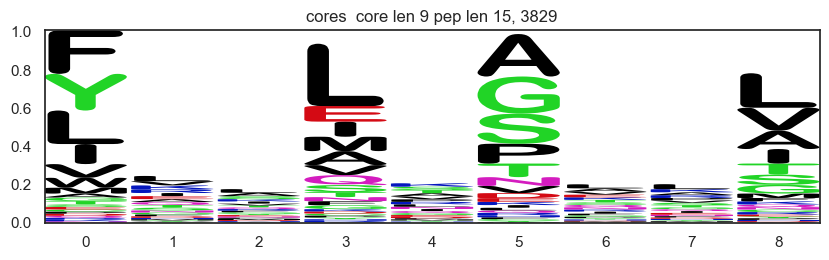

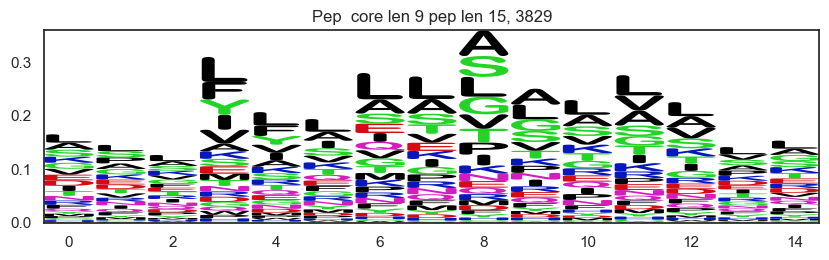

In [52]:
target_peptide_len = 15
target_core_len = 9

df = restricted_motif(total_df, peptide_len=target_peptide_len, core_len=target_core_len, use_peptides=True)




C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


found different lengths. Took max. deleted 19 peptides


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


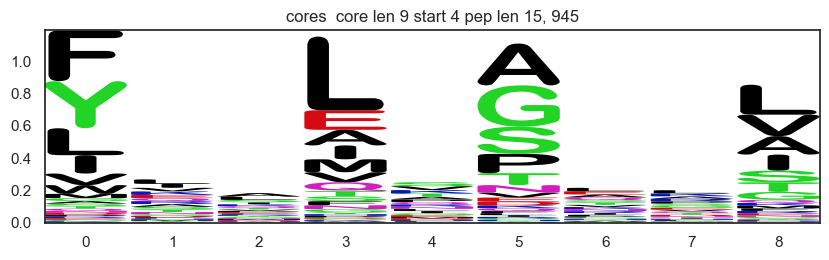

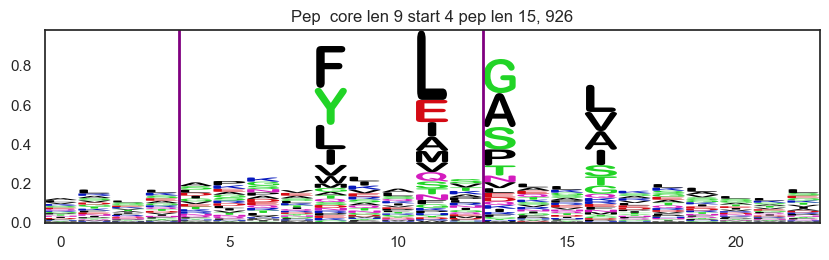

In [515]:
target_peptide_len = 15
target_core_len = 9
core_start = 4

df = restricted_motif(total_df,
                      peptide_len=target_peptide_len, core_len=target_core_len, core_start=core_start,
                      use_peptides=True, mark_left=core_start, mark_right=core_start+target_core_len)



## Show motifs for padded

In [189]:
total_df.head(10)

,simplified_path,peptide,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Parent Species,measurement_value,...,peptide_start,peptide_end,measurement_type,Measurement Inequality,binder,length,protein_id,protein,new_peptide,new_peptide_len
VGPLTVNEKRRLKLI,"[1.03, 2.04, 5.11, 9.26, 12.34, 15.43, 15.43, ...",VGPLTVNEKRRLKLI,3,11,9,15,LTVNEKRRL,"[9.26, 12.34, 15.43, 15.43, 15.43, 15.43, 14.4...",Hepatitis B virus,8415.0,...,96.0,110.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,CQQYVGPLTVNEKRRLKLIMPAR,23
RHYLHTLWKAGILYK,"[1.03, 3.07, 7.14, 7.14, 8.15, 10.24, 15.36, 1...",RHYLHTLWKAGILYK,4,12,9,15,HTLWKAGIL,"[8.15, 10.24, 15.36, 15.36, 15.36, 14.33, 12.2...",Hepatitis B virus,17.0,...,145.0,159.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,YFKTRHYLHTLWKAGILYKRETT,23
ESRLVVDFSQFSRGN,"[1.0, 1.0, 3.05, 9.14, 13.23, 14.24, 15.28, 15...",ESRLVVDFSQFSRGN,3,11,9,15,LVVDFSQFS,"[9.14, 13.23, 14.24, 15.28, 15.28, 15.28, 14.2...",Hepatitis B virus,7372.0,...,385.0,399.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,HNTTESRLVVDFSQFSRGSTHVS,23
LQSLTNLLSSNLSWL,"[1.0, 1.0, 3.02, 9.25, 15.44, 15.44, 15.44, 15...",LQSLTNLLSSNLSWL,3,11,9,15,LTNLLSSNL,"[9.25, 15.44, 15.44, 15.44, 15.44, 15.44, 14.4...",Hepatitis B virus,2.0,...,412.0,426.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,AVPNLQSLTNLLSSNLSWLSLDV,23
SSNLSWLSLDVSAAF,"[1.01, 1.01, 1.01, 1.01, 4.02, 13.06, 15.1, 15...",SSNLSWLSLDVSAAF,5,13,9,15,WLSLDVSAA,"[13.06, 15.1, 15.1, 15.1, 14.09, 14.09, 14.09,...",Hepatitis B virus,38.0,...,420.0,434.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,TNLLSSNLSWLSLDVSAAFYHIP,23
LHLYSHPIILGFRKI,"[1.03, 2.09, 4.12, 5.14, 6.2, 12.48, 15.57, 15...",LHLYSHPIILGFRKI,5,13,9,15,HPIILGFRK,"[12.48, 15.57, 15.57, 15.57, 14.54, 13.48, 11....",Hepatitis B virus,248.0,...,501.0,515.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,FGRKLHLYSHPIILGFRKIPMGV,23
AANWILRGTSFVYVP,"[0.0, 3.02, 5.1, 9.2, 12.26, 15.37, 15.37, 15....",AANWILRGTSFVYVP,3,11,9,15,WILRGTSFV,"[9.2, 12.26, 15.37, 15.37, 15.37, 15.37, 15.37...",Hepatitis B virus,55.0,...,767.0,781.0,quantitative,NaN,1,15,Q69028,MPLSYQHFRKLLLLDDEAGPLEEELPRLADEGLNRRVAEDLNLGNL...,LLGCAANWILRGTSFVYVPSALN,23
DALESIMTTKSVSFR,"[0.0, 4.06, 12.28, 14.3, 15.3, 15.3, 15.3, 15....",DALESIMTTKSVSFR,2,10,9,15,LESIMTTKS,"[12.28, 14.3, 15.3, 15.3, 15.3, 15.3, 15.3, 15...",Rabies lyssavirus,385.0,...,304.0,318.0,quantitative,NaN,1,15,P08667,MVPQALLFVPLLVFPLCFGKFPIYTIPDKLGPWSPIDIHHLSCPNN...,EECLDALESIMTTKSVSFRRLSH,23
DNVLDHLTGRSC,"[1.0, 1.0, 11.11, 15.16, 15.16, 15.16, 15.16, ...",DNVLDHLTGRSC,2,10,9,12,VLDHLTGRS,"[11.11, 15.16, 15.16, 15.16, 15.16, 15.16, 15....",Bordetella pertussis,455.0,...,64.0,75.0,quantitative,NaN,1,12,P04977,MRCTRAIRQTARTGWLTWLAILAVTAPVTSPAWADDPPATVYRYDS...,WGNNDNVLDHLTGRSCQVGS,20
DTPYLDITYHFVMQRLPL,"[1.01, 1.01, 3.06, 8.13, 8.13, 8.13, 9.19, 11....",DTPYLDITYHFVMQRLPL,3,11,9,18,YLDITYHFV,"[8.13, 8.13, 8.13, 9.19, 11.22, 13.22, 14.27, ...",Homo sapiens,250.0,...,240.0,257.0,quantitative,NaN,1,18,P02708,MEPWPLLLLFSLCSAGLVLGSEHETRLVAKLFKDYSSVVRPVEDHR...,SCCPDTPYLDITYHFVMQRLPLYFIV,26


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


found different lengths. Took max. deleted 19 peptides


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T


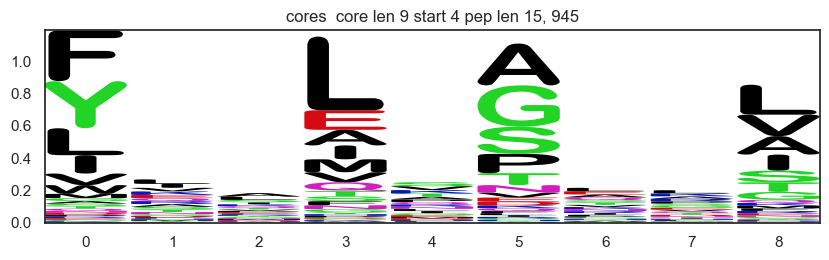

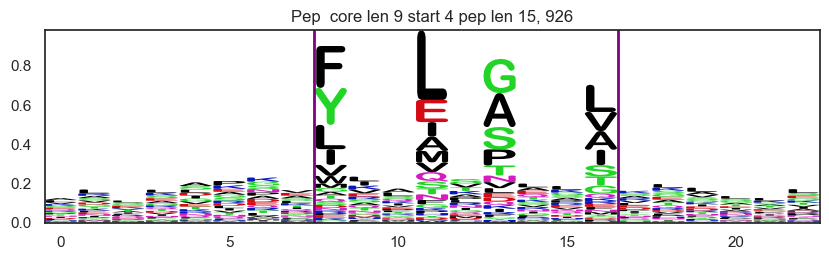

In [516]:
target_peptide_len = 15
target_core_len = 9
core_start = 4

df = restricted_motif(total_df,
                      peptide_len=target_peptide_len, core_len=target_core_len, core_start=core_start,
                      use_peptides=True, mark_left=pad_value + core_start, mark_right=pad_value + core_start+target_core_len, peptide_column='new_peptide')

number of columns 7
number of rows 10
0


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

1


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

2


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

... (4 outputs left out)

5


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

6


C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  counts_df.loc[:, c] = tmp_mat.sum(axis=0).T
C:\Tools\Anaconda\envs\pomegranate\lib\site-packages\logomaker\src\matrix.py:584: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a n

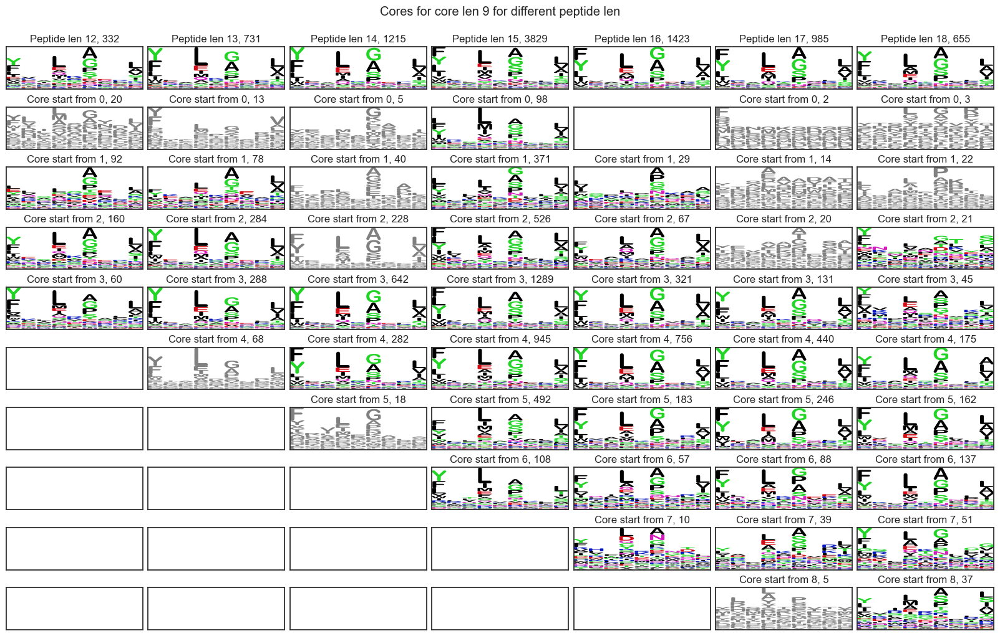

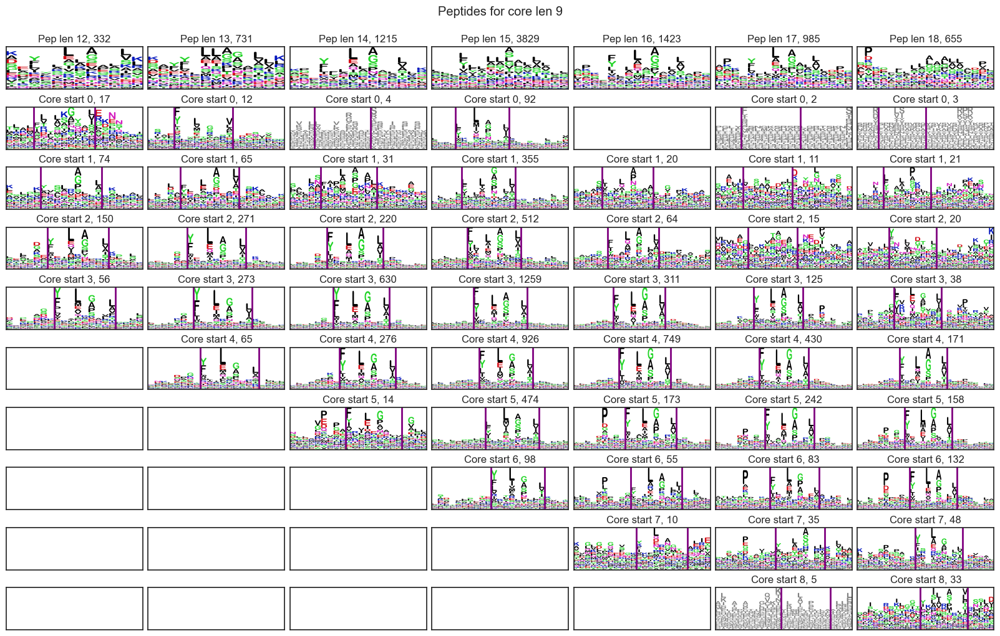

In [53]:
show_shift_subsets(total_df=total_df, target_core_len=9, need_mark_left=True, need_mark_right=True,
                   peptide_to_draw_column='new_peptide', add_factor=4
                   )

# OLDER

## Parse Gibbs result

In [494]:
GIBBS_RESULT_PATH = 'gibbs_result/mhcII_1682382/res/gibbs.1g.ds.out'

In [495]:
gibbs_result = pd.read_csv(GIBBS_RESULT_PATH, delimiter=r"\s+")
gibbs_result.index = gibbs_result['Sequence']
gibbs_result = gibbs_result[['Core']].rename(columns={"Core": "Gibbs_core"})

FileNotFoundError: [Errno 2] No such file or directory: 'gibbs_result/mhcII_1682382/res/gibbs.1g.ds.out'

In [ ]:
filtered = total_df[total_df['peptide_len'] == 15]
filtered = filtered.join(gibbs_result)

In [ ]:
filtered

In [ ]:
len(filtered[filtered.Gibbs_core.notnull()])

In [ ]:
df_same_cores = filtered[filtered['core_peptide'] == filtered['Gibbs_core']]
len(df_same_cores)

In [ ]:
df_our_contains_gibbs =  filtered[filtered.apply(lambda row: str(row['Gibbs_core']) in row['core_peptide']  , axis=1)]
df_our_contains_gibbs = df_our_contains_gibbs.loc[df_our_contains_gibbs.index.difference(df_same_cores.index)]
len(df_our_contains_gibbs)

In [ ]:
df_our_contains_gibbs

In [ ]:
df_our_contains_gibbs.groupby('peptide_len')['core_len'].value_counts()

In [ ]:
df_gibbs_contains_our =  filtered[filtered.apply(lambda row:  row['core_peptide'] in str(row['Gibbs_core']) , axis=1)]
df_gibbs_contains_our = df_gibbs_contains_our.loc[df_gibbs_contains_our.index.difference(df_same_cores.index)]
len(df_gibbs_contains_our)

In [ ]:
df_gibbs_contains_our

In [ ]:
df_gibbs_contains_our['core_len'].value_counts()

In [ ]:
gibbs_not_null = filtered[filtered.Gibbs_core.notnull()]

In [ ]:
different_cores = gibbs_not_null.loc[gibbs_not_null.index.difference(df_gibbs_contains_our.index).difference(df_same_cores.index).difference(df_our_contains_gibbs.index)]

In [ ]:
different_cores['core_len'].value_counts()

In [67]:
gibbs_null = filtered[filtered.Gibbs_core.isnull()]

In [68]:
filtered['core_peptide'].str.startswith(filtered['Gibbs_core'])

DEVLIEVNPPFGDSY   NaN
KLATSVLAGLLGVVS   NaN
APHYYEQTRGGQVSV   NaN
VKPLYIITPTNVSHI   NaN
KLPLGINITNFRAIL   NaN
                   ..
QDRQGKTPLTLVDLC   NaN
VNHFVPEAGSRLDQR   NaN
WSLTDSSGKDTPGGY   NaN
CDLFKKHDDAIVRLR   NaN
KRREGMFIDEKPGNR   NaN
Name: core_peptide, Length: 6694, dtype: float64

In [46]:
gibbs_null[gibbs_null['core_len'] == 9]

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core


In [47]:
gibbs_null.core_len.value_counts()

12    1563
13    1101
14     333
15      27
Name: core_len, dtype: int64

In [47]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

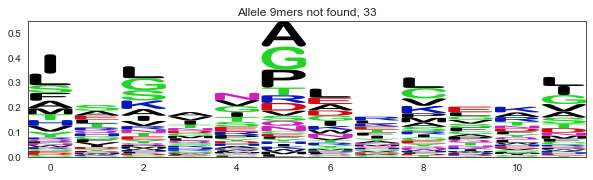

In [443]:
not_found_9 = gibbs_null[gibbs_null['core_len'] == 12]
make_logo_for_data(not_found_9['core_peptide'].values, "9mers not found")

## Cluster cores

In [40]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
KTEYISTEFNRYG,"[0.0, 0.0, 0.0, 5.87, 0.0, 0.0, 3.54, 0.0, 5.8...",3,8,6,13,YISTEF,"[5.87, 0.0, 0.0, 3.54, 0.0, 5.87]"
SIAAVEMEHFLPL,"[0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0, 5.05, 0.0...",4,9,6,13,VEMEHF,"[6.25, 0.0, 0.0, 5.05, 0.0, 6.25]"
KNGFKTQHFVSAK,"[0.0, 0.0, 0.0, 6.08, 0.0, 0.0, 2.4, 0.0, 6.08...",3,8,6,13,FKTQHF,"[6.08, 0.0, 0.0, 2.4, 0.0, 6.08]"
GSSFVGQLFNQHP,"[0.0, 0.0, 0.0, 6.09, 0.0, 0.0, 2.47, 0.0, 6.0...",3,8,6,13,FVGQLF,"[6.09, 0.0, 0.0, 2.47, 0.0, 6.09]"
IMNSFVNDIFERI,"[0.0, 0.0, 0.0, 0.0, 6.13, 0.0, 0.0, 2.51, 0.0...",4,9,6,13,FVNDIF,"[6.13, 0.0, 0.0, 2.51, 0.0, 6.13]"
...,...,...,...,...,...,...,...
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 0.0, 0.0, 5.12, 0.0, 0.0, 5.09, 0.0...",4,12,9,18,AKPEASFQV,"[5.12, 0.0, 0.0, 5.09, 0.0, 5.12, 2.63, 0.0, 2..."
LPLTVTSQQGVKVKFPPN,"[0.0, 0.0, 0.0, 0.0, 6.1, 0.0, 0.0, 2.48, 0.0,...",4,12,9,18,VTSQQGVKV,"[6.1, 0.0, 0.0, 2.48, 0.0, 6.1, 0.0, 0.0, 1.2]"
GPKPVVFLQHGLLADSSN,"[0.0, 0.0, 0.0, 0.0, 3.9, 2.59, 0.0, 1.31, 1.3...",4,12,9,18,VVFLQHGLL,"[3.9, 2.59, 0.0, 1.31, 1.31, 0.0, 6.49, 0.0, 1..."
TGGKYIGERSVRVWGHRF,"[0.0, 0.0, 0.0, 0.0, 5.92, 0.0, 0.0, 4.72, 0.0...",4,12,9,18,YIGERSVRV,"[5.92, 0.0, 0.0, 4.72, 0.0, 5.92, 0.0, 0.0, 2.3]"


In [41]:
total_df.core_len.value_counts()

9     8793
6     4449
8     2274
10    2221
7     1784
11     469
12     132
5       90
13      29
14       4
4        3
15       1
Name: core_len, dtype: int64

In [42]:
# total_df['simplified_path_2'] = total_df['simplified_path'].apply(lambda x: (x> 0).astype(int))
target_peptide_len = [15,16, 17,18]
core_len = 9
target_column_to_cluster = 'core_path'

filtered = total_df[total_df['peptide_len'].isin(target_peptide_len)]
filtered = filtered[filtered['core_len'] == core_len]


In [43]:
filtered

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
RPVLRASSFQPISGN,"[0.0, 0.0, 0.0, 5.98, 0.0, 0.0, 2.41, 0.0, 5.9...",3,11,9,15,LRASSFQPI,"[5.98, 0.0, 0.0, 2.41, 0.0, 5.98, 0.0, 0.0, 2.45]"
DGKVYYTDVFLDVIR,"[0.0, 0.0, 0.0, 0.0, 6.25, 0.0, 0.0, 3.8, 0.0,...",4,12,9,15,YYTDVFLDV,"[6.25, 0.0, 0.0, 3.8, 0.0, 6.25, 0.0, 0.0, 2.48]"
KGHIIVDEFQNTNVK,"[0.0, 0.0, 0.0, 6.26, 0.0, 0.0, 3.79, 0.0, 6.2...",3,11,9,15,IIVDEFQNT,"[6.26, 0.0, 0.0, 3.79, 0.0, 6.26, 0.0, 0.0, 1.25]"
HKPVQASYFETLRQG,"[0.0, 0.0, 0.0, 6.18, 0.0, 0.0, 2.51, 0.0, 6.1...",3,11,9,15,VQASYFETL,"[6.18, 0.0, 0.0, 2.51, 0.0, 6.18, 0.0, 0.0, 1.31]"
QPTPFVSLFFQRLLR,"[0.0, 0.0, 0.0, 0.0, 6.09, 0.0, 0.0, 3.59, 0.0...",4,12,9,15,FVSLFFQRL,"[6.09, 0.0, 0.0, 3.59, 0.0, 6.09, 0.0, 0.0, 2.4]"
...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 6.41, 0.0,...",7,15,9,18,YSWAVAQGV,"[6.41, 0.0, 0.0, 2.53, 0.0, 6.41, 0.0, 0.0, 1.23]"
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 0.0, 0.0, 5.12, 0.0, 0.0, 5.09, 0.0...",4,12,9,18,AKPEASFQV,"[5.12, 0.0, 0.0, 5.09, 0.0, 5.12, 2.63, 0.0, 2..."
LPLTVTSQQGVKVKFPPN,"[0.0, 0.0, 0.0, 0.0, 6.1, 0.0, 0.0, 2.48, 0.0,...",4,12,9,18,VTSQQGVKV,"[6.1, 0.0, 0.0, 2.48, 0.0, 6.1, 0.0, 0.0, 1.2]"
GPKPVVFLQHGLLADSSN,"[0.0, 0.0, 0.0, 0.0, 3.9, 2.59, 0.0, 1.31, 1.3...",4,12,9,18,VVFLQHGLL,"[3.9, 2.59, 0.0, 1.31, 1.31, 0.0, 6.49, 0.0, 1..."


In [44]:
for i in range(core_len):
    filtered[i] = filtered[target_column_to_cluster].map(lambda x :  x[i])

In [45]:
from sklearn.decomposition import PCA

# overwrite for non-linear test
def get_pca(X, n_components=2, whiten=True):
    pca = PCA(n_components=n_components, whiten=whiten)
    X = X
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca


In [46]:
from sklearn.preprocessing import StandardScaler
values_to_run_clustering_on = filtered[[i for i in range(core_len)]].copy() #+ ['norm_vi_prob']

unique_values_to_run_clustering_on = values_to_run_clustering_on.copy().drop_duplicates() #+ ['norm_vi_prob']
values_to_run_clustering_on = unique_values_to_run_clustering_on
values_to_run_clustering_on.loc[:, [i for i in range(core_len)]] = StandardScaler().fit_transform(values_to_run_clustering_on)
result = filtered.loc[values_to_run_clustering_on.index].copy()

pca = get_pca(values_to_run_clustering_on)


Shape (6771, 9)
Explained variation per principal component: [0.41792236 0.17012156]


In [47]:
values_to_run_clustering_on

,0,1,2,3,4,5,6,7,8
RPVLRASSFQPISGN,0.265954,-0.298929,-0.241288,-0.880014,-0.282815,0.262061,-0.332605,-0.328437,0.593159
DGKVYYTDVFLDVIR,0.455869,-0.298929,-0.241288,0.202863,-0.282815,0.440192,-0.332605,-0.328437,0.629332
KGHIIVDEFQNTNVK,0.462903,-0.298929,-0.241288,0.195073,-0.282815,0.446789,-0.332605,-0.328437,-0.853763
HKPVQASYFETLRQG,0.406632,-0.298929,-0.241288,-0.802109,-0.282815,0.394010,-0.332605,-0.328437,-0.781417
QPTPFVSLFFQRLLR,0.343327,-0.298929,-0.241288,0.039263,-0.282815,0.334633,-0.332605,-0.328437,0.532871
...,...,...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,0.568411,-0.298929,-0.241288,-0.786528,-0.282815,0.545751,-0.332605,-0.328437,-0.877878
GLAKAKPEASFQVWNKDS,-0.338959,-0.298929,-0.241288,1.207836,-0.282815,-0.305319,1.864035,-0.328437,0.665506
LPLTVTSQQGVKVKFPPN,0.350361,-0.298929,-0.241288,-0.825481,-0.282815,0.341230,-0.332605,-0.328437,-0.914051
GPKPVVFLQHGLLADSSN,-1.197091,2.181097,-0.241288,-1.736967,1.354878,-3.683207,5.088001,-0.328437,-0.829647


In [48]:
values_to_run_clustering_on

,0,1,2,3,4,5,6,7,8
RPVLRASSFQPISGN,0.265954,-0.298929,-0.241288,-0.880014,-0.282815,0.262061,-0.332605,-0.328437,0.593159
DGKVYYTDVFLDVIR,0.455869,-0.298929,-0.241288,0.202863,-0.282815,0.440192,-0.332605,-0.328437,0.629332
KGHIIVDEFQNTNVK,0.462903,-0.298929,-0.241288,0.195073,-0.282815,0.446789,-0.332605,-0.328437,-0.853763
HKPVQASYFETLRQG,0.406632,-0.298929,-0.241288,-0.802109,-0.282815,0.394010,-0.332605,-0.328437,-0.781417
QPTPFVSLFFQRLLR,0.343327,-0.298929,-0.241288,0.039263,-0.282815,0.334633,-0.332605,-0.328437,0.532871
...,...,...,...,...,...,...,...,...,...
DPDSRGEYSWAVAQGVKQ,0.568411,-0.298929,-0.241288,-0.786528,-0.282815,0.545751,-0.332605,-0.328437,-0.877878
GLAKAKPEASFQVWNKDS,-0.338959,-0.298929,-0.241288,1.207836,-0.282815,-0.305319,1.864035,-0.328437,0.665506
LPLTVTSQQGVKVKFPPN,0.350361,-0.298929,-0.241288,-0.825481,-0.282815,0.341230,-0.332605,-0.328437,-0.914051
GPKPVVFLQHGLLADSSN,-1.197091,2.181097,-0.241288,-1.736967,1.354878,-3.683207,5.088001,-0.328437,-0.829647


In [49]:
pca_result = pca.transform(values_to_run_clustering_on)

result[['pca0', 'pca1']] = pca_result


In [56]:
from sklearn.cluster import DBSCAN, KMeans

# clustering  = DBSCAN( min_samples=200, eps=1)
clustering = KMeans(n_clusters=10).fit(values_to_run_clustering_on)
clustering_result =clustering.predict(values_to_run_clustering_on)
# for optics
# clustering.fit_predict(values_to_run_clustering_on)
# clustering_result = clustering.labels_

clustering_result

array([2, 0, 7, ..., 7, 1, 0])

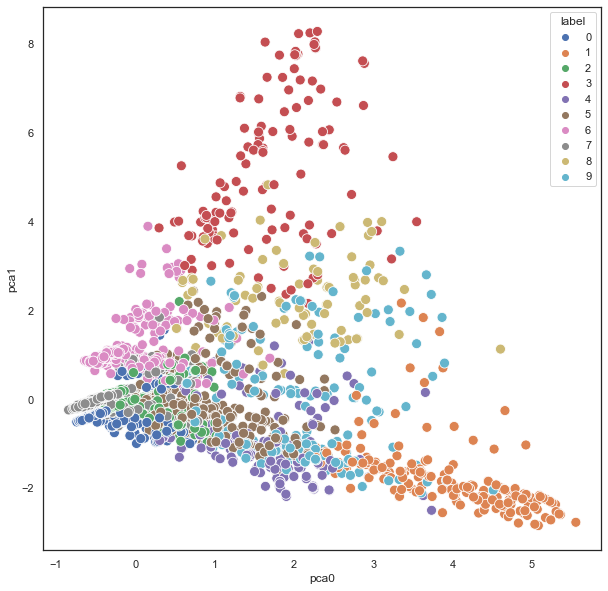

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(10, 10))
result['label'] = clustering_result
graph = sns.scatterplot(data=result, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

In [119]:
result.loc[((result['pca0'] > 0) & (result['pca1'] > 0)), 'new_label'] = "1,1"
result.loc[((result['pca0'] > 0) & (result['pca1'] <= 0)), 'new_label'] = "1,-1"
result.loc[((result['pca0'] <= 0) & (result['pca1'] <= 0)), 'new_label'] = "-1,-1"
result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0)), 'new_label'] = "-1,1_0"

#
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0.4)), 'new_label'] = "-1,1_1"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 0.8)), 'new_label'] = "-1,1_2"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 1)), 'new_label'] = "-1,1_3"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 1.7)), 'new_label'] = "-1,1_4"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] > 2.3)), 'new_label'] = "-1,1_5"
# result.loc[((result['pca0'] <= 0) & (result['pca1'] <= -0.7)), 'new_label'] = "-1,-1_down"
result.loc[((result['pca0'] > 0) & (result['pca1'] <= -0.7)), 'new_label'] = "1,-1_down"
result.loc[((result['pca0'] > 0.5) & (result['pca1'] <= -0.7)), 'new_label'] = "1,-1_down_0.5"

result.loc[((result['pca0'] > 1) & (result['pca1'] <= 0)), 'new_label'] = "rest"

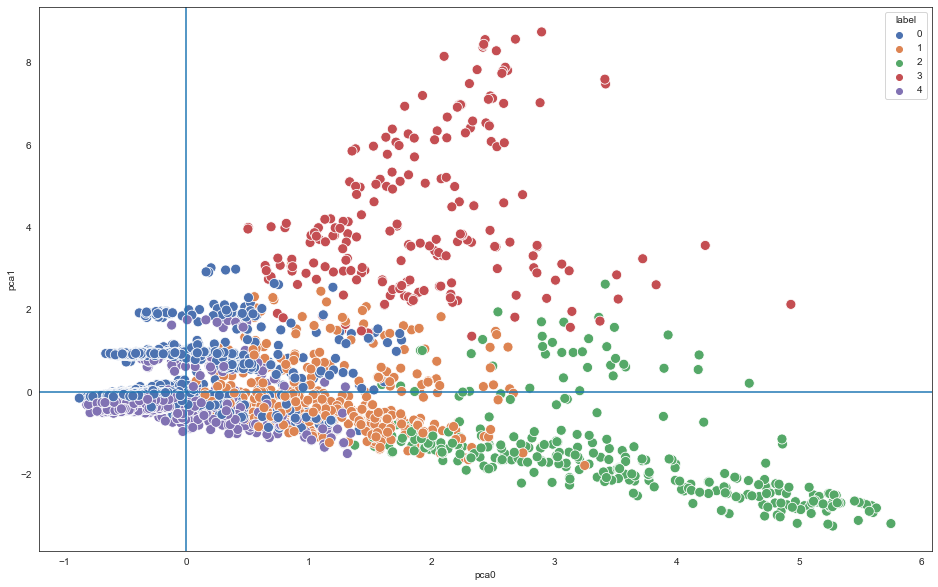

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
result['label'] = clustering_result
graph = sns.scatterplot(data=result, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)
graph.axhline(0)
graph.axvline(0)

In [58]:
pd.crosstab(result['label'], result['core_len'], values=result.index, aggfunc='count').fillna(0).astype(int)

core_len,9
label,
0,1872
1,188
2,876
3,127
4,162
5,330
6,621
7,2327
8,81


In [59]:
pd.DataFrame(result.groupby(['label', 'core_len'],as_index=False).size())#.pivot(index='size', columns=['label', 'core_len'])

,label,core_len,size
0,0,9,1872
1,1,9,188
2,2,9,876
3,3,9,127
4,4,9,162
5,5,9,330
6,6,9,621
7,7,9,2327
8,8,9,81
9,9,9,187


In [60]:
result.label.value_counts()

7    2327
0    1872
2     876
6     621
5     330
1     188
9     187
4     162
3     127
8      81
Name: label, dtype: int64

In [54]:
result.peptide_len.value_counts()

15    3574
16    1534
17    1018
18     645
Name: peptide_len, dtype: int64

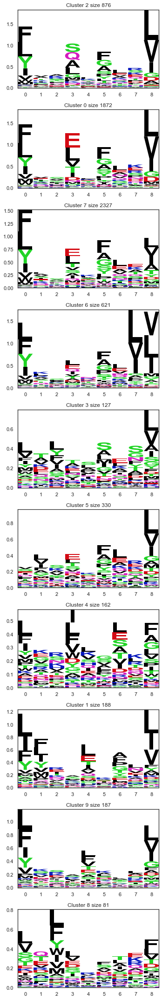

In [61]:
label_to_draw = 'label'

import logomaker
import matplotlib.pyplot as plt
unique_labels = result[label_to_draw].unique()
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3*len(unique_labels)))
for i, label in enumerate(unique_labels):
    filtered_for_label = result[result[label_to_draw] == label]
    if len(filtered_for_label) > 0:
        matrix = logomaker.alignment_to_matrix(filtered_for_label['core_peptide'].values)

        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        ww_logo = logomaker.Logo(info_matrix,
                                 # font_name='Arial Rounded MT Bold',
                                 ax=axes[i]
                                 )
        ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()


In [326]:
result[result.new_label == "-1,-1"]


,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,0,1,2,3,4,5,6,7,8,pca0,pca1,label,new_label
SPSIVIALAGNKADL,"[0.0, 0.0, 0.0, 0.0, 3.82, 0.0, 0.0, 3.82, 0.0...",4,12,9,15,VIALAGNKA,"[3.82, 0.0, 0.0, 3.82, 0.0, 3.82, 0.0, 0.0, 3.05]",3.82,0.0,0.0,3.82,0.0,3.82,0.0,0.00,3.05,-0.739755,-0.457546,4,"-1,-1"
KGNLVELGSFYSDPK,"[0.0, 0.0, 0.0, 3.73, 0.0, 0.0, 3.73, 0.0, 3.7...",3,11,9,15,LVELGSFYS,"[3.73, 0.0, 0.0, 3.73, 0.0, 3.73, 0.0, 0.0, 2.99]",3.73,0.0,0.0,3.73,0.0,3.73,0.0,0.00,2.99,-0.653505,-0.417899,4,"-1,-1"
LLKDVEYARPGLISS,"[0.0, 0.0, 0.0, 0.0, 3.65, 0.0, 0.0, 3.65, 0.0...",4,12,9,15,VEYARPGLI,"[3.65, 0.0, 0.0, 3.65, 0.0, 3.65, 0.0, 0.0, 2.96]",3.65,0.0,0.0,3.65,0.0,3.65,0.0,0.00,2.96,-0.578709,-0.401874,4,"-1,-1"
ADNFLLENTLPAQST,"[0.0, 0.0, 0.0, 3.96, 0.0, 0.0, 3.96, 0.0, 3.9...",3,11,9,15,FLLENTLPA,"[3.96, 0.0, 0.0, 3.96, 0.0, 3.96, 0.0, 0.0, 3.18]",3.96,0.0,0.0,3.96,0.0,3.96,0.0,0.00,3.18,-0.876862,-0.549419,4,"-1,-1"
QKSIVAYTMSLGADS,"[0.0, 0.0, 0.0, 0.0, 3.34, 0.0, 0.0, 3.34, 0.0...",4,12,9,15,VAYTMSLGA,"[3.34, 0.0, 0.0, 3.34, 0.0, 3.34, 0.0, 0.0, 2.64]",3.34,0.0,0.0,3.34,0.0,3.34,0.0,0.00,2.64,-0.272537,-0.171969,4,"-1,-1"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SSFGSGAGSSSFSRTSSS,"[0.0, 0.0, 3.02, 0.0, 0.0, 3.04, 0.0, 3.79, 0....",2,10,9,18,FGSGAGSSS,"[3.02, 0.0, 0.0, 3.04, 0.0, 3.79, 0.0, 0.0, 3.04]",3.02,0.0,0.0,3.04,0.0,3.79,0.0,0.00,3.04,-0.249466,-0.540437,4,"-1,-1"
DGNLRPWWKNSSVEAFKQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.8, 0.0, 0.0, ...",6,14,9,18,WWKNSSVEA,"[3.8, 0.0, 0.0, 3.0, 0.0, 3.8, 0.0, 0.0, 3.02]",3.80,0.0,0.0,3.00,0.0,3.80,0.0,0.00,3.02,-0.475445,-0.466787,4,"-1,-1"
RDDGSWEVIEGYRAQHSQ,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.9, 0.0, 0.0, 3.17,...",5,13,9,18,WEVIEGYRA,"[3.9, 0.0, 0.0, 3.17, 0.0, 3.9, 0.0, 0.0, 3.12]",3.90,0.0,0.0,3.17,0.0,3.90,0.0,0.00,3.12,-0.595285,-0.535513,4,"-1,-1"
DVSRFKAIKARFAKPVYP,"[0.0, 0.0, 0.0, 0.0, 4.0, 0.0, 0.0, 4.0, 0.0, ...",4,12,9,18,FKAIKARFA,"[4.0, 0.0, 0.0, 4.0, 0.0, 4.0, 0.0, 0.0, 3.19]",4.00,0.0,0.0,4.00,0.0,4.00,0.0,0.00,3.19,-0.913859,-0.553313,4,"-1,-1"


In [ ]:
target_df  = result[result.label == 2].copy()
target_df['peptide'] = target_df.index.values
target_df['peptide'].to_csv("gibbs_input.csv", index=False, header=False)

In [254]:
target_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,0,1,2,3,4,5,6,7,8,pca0,pca1,label,peptide
DSMKALKDALSFHND,"[0.0, 0.0, 3.02, 0.0, 0.0, 3.79, 0.0, 3.79, 0....",2,10,9,15,MKALKDALS,"[3.02, 0.0, 0.0, 3.79, 0.0, 3.79, 0.0, 0.74, 2...",3.02,0.0,0.00,3.79,0.00,3.79,0.0,0.74,2.28,-0.408894,0.485584,2,DSMKALKDALSFHND
KMMNMEAANLAEVRS,"[0.0, 0.0, 2.88, 0.0, 0.71, 2.88, 0.71, 2.88, ...",2,10,9,15,MNMEAANLA,"[2.88, 0.0, 0.71, 2.88, 0.71, 2.88, 0.0, 1.41,...",2.88,0.0,0.71,2.88,0.71,2.88,0.0,1.41,1.47,0.406412,1.460920,2,KMMNMEAANLAEVRS
SEDEIRQTLDYRWVN,"[0.0, 0.0, 0.0, 0.0, 3.58, 0.0, 0.0, 2.9, 0.0,...",4,12,9,15,IRQTLDYRW,"[3.58, 0.0, 0.0, 2.9, 0.0, 3.58, 0.0, 0.0, 0.73]",3.58,0.0,0.00,2.90,0.00,3.58,0.0,0.00,0.73,-0.129294,1.400140,2,SEDEIRQTLDYRWVN
KERQIKKQTALVELV,"[0.0, 0.0, 0.0, 0.0, 3.75, 0.0, 0.0, 3.75, 0.0...",4,12,9,15,IKKQTALVE,"[3.75, 0.0, 0.0, 3.75, 0.0, 3.75, 0.0, 1.56, 0...",3.75,0.0,0.00,3.75,0.00,3.75,0.0,1.56,0.69,-0.469882,2.259168,2,KERQIKKQTALVELV
FPQVGGLTSIKWADN,"[0.0, 0.0, 0.0, 3.74, 0.0, 0.0, 3.74, 0.0, 3.7...",3,11,9,15,VGGLTSIKW,"[3.74, 0.0, 0.0, 3.74, 0.0, 3.74, 0.0, 0.0, 1.53]",3.74,0.0,0.00,3.74,0.00,3.74,0.0,0.00,1.53,-0.545466,0.785639,2,FPQVGGLTSIKWADN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAKREINKLLKQKEKKNE,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.63, 0.0, 0.0, 3.63...",5,13,9,18,INKLLKQKE,"[3.63, 0.0, 0.0, 3.63, 0.0, 2.84, 0.0, 0.0, 0.68]",3.63,0.0,0.00,3.63,0.00,2.84,0.0,0.00,0.68,-0.143519,1.478982,2,MAKREINKLLKQKEKKNE
YTSGPGSRISSSSFSRVG,"[0.0, 0.0, 0.0, 0.0, 0.0, 2.07, 0.0, 0.0, 2.8,...",5,13,9,18,GSRISSSSF,"[2.07, 0.0, 0.0, 2.8, 0.0, 3.45, 0.0, 1.34, 0.73]",2.07,0.0,0.00,2.80,0.00,3.45,0.0,1.34,0.73,0.412997,1.953667,2,YTSGPGSRISSSSFSRVG
QHDKLVRLYAVVTKEEPI,"[0.0, 0.0, 0.0, 0.0, 3.88, 0.0, 0.0, 3.88, 0.0...",4,12,9,18,LVRLYAVVT,"[3.88, 0.0, 0.0, 3.88, 0.0, 3.88, 0.0, 0.79, 2.3]",3.88,0.0,0.00,3.88,0.00,3.88,0.0,0.79,2.30,-0.725155,0.561979,2,QHDKLVRLYAVVTKEEPI
DQEHIMEHLEGVINKPEA,"[0.0, 0.0, 0.0, 0.0, 0.0, 3.74, 0.0, 0.0, 3.74...",5,13,9,18,MEHLEGVIN,"[3.74, 0.0, 0.0, 3.74, 0.0, 3.74, 0.0, 1.51, 0...",3.74,0.0,0.00,3.74,0.00,3.74,0.0,1.51,0.74,-0.465397,2.191883,2,DQEHIMEHLEGVINKPEA


In [201]:
target_df['core_peptide']

KMMNMEAANLAEVRS       MNMEAANLA
KERQIKKQTALVELV       IKKQTALVE
NPKNFQTMPGTFQTT       FQTMPGTFQ
FGLSYKEQVGSNREL       YKEQVGSNR
EVKSFQWTQALRREL       FQWTQALRR
                        ...    
LHGQFSQAVTPLAHHHTD    FSQAVTPLA
MAKREINKLLKQKEKKNE    INKLLKQKE
YTSGPGSRISSSSFSRVG    GSRISSSSF
DQEHIMEHLEGVINKPEA    MEHLEGVIN
VPNQYNPLRGSVAPGPLS    YNPLRGSVA
Name: core_peptide, Length: 786, dtype: object

In [139]:
input_with_label = result[[i for i in range(9)] + ['label', 'core_peptide']]

In [143]:
pd.DataFrame(input_with_label.groupby('label').sum().loc[2]).T

,0,1,2,3,4,5,6,7,8
2,2913.61,2932.54,2933.28,2952.91,2952.91,2952.91,2716.02,2712.49,2362.99


In [463]:
input_with_label[input_with_label['label'] == 4]

,0,1,2,3,4,5,6,7,8,label,core_peptide
LRNLCELLGVEPPSE,2.10,3.48,3.48,3.48,3.48,3.48,2.08,0.70,0.70,4,LCELLGVEP
NPKNFQTMPGTFQTT,3.65,3.65,3.65,3.65,3.65,3.65,0.73,0.73,0.73,4,FQTMPGTFQ
GPSPKQLVSLGPEKS,2.18,2.18,2.18,3.59,3.59,3.59,1.41,1.41,1.41,4,PKQLVSLGP
FGLSYKEQVGSNREL,3.73,3.73,3.73,3.73,3.73,3.73,0.74,0.74,0.74,4,YKEQVGSNR
EVKSFQWTQALRREL,3.71,3.71,3.71,3.71,3.71,3.71,0.74,0.74,0.74,4,FQWTQALRR
...,...,...,...,...,...,...,...,...,...,...,...
VGHVDEFLSFVPAPDRKG,3.69,3.69,3.69,3.69,3.69,3.69,0.72,0.72,0.72,4,FLSFVPAPD
TYNIADAARHYGVNLNTL,2.98,2.98,2.98,3.72,3.72,3.72,1.50,1.50,1.50,4,YNIADAARH
LTQYFVQENYLEYRQVPG,1.47,3.81,3.81,3.81,3.81,3.81,3.81,0.70,0.70,4,YFVQENYLE
EKGPMFELLPGESNKIPR,3.70,3.70,3.70,3.70,3.70,3.70,1.44,1.44,0.73,4,FELLPGESN


<AxesSubplot:>

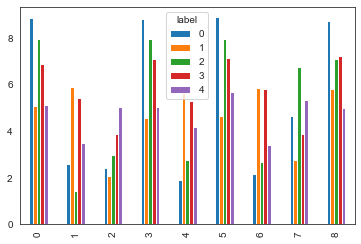

In [108]:
np.log(input_with_label.groupby('label').sum()).T.plot(kind='bar')

In [172]:
input_with_label.groupby('label').sum()

,0,1,2,3,4,5,6,7,8
label,,,,,,,,,
0,6.831630,5.404523,3.909219,7.063955,5.305293,7.090685,5.829093,3.875152,7.190510
1,7.939341,1.423108,2.962175,7.931101,2.775086,7.938199,2.619583,6.738686,7.084151
2,8.840097,2.714032,2.418589,8.827823,1.993339,8.895813,2.227862,4.616802,8.711641
3,5.163471,3.479700,5.041940,5.047032,4.172077,5.690191,3.382354,5.340658,5.011368
4,5.059044,5.885715,2.071913,4.539564,5.917199,4.652245,5.840613,2.693951,5.806429


In [164]:
input_with_label[input_with_label.label == 1].sum(axis=0)

0        2805.51
1           4.15
2          19.34
3        2782.49
4          16.04
5        2802.31
6          13.73
7         844.45
8        1192.91
label     799.00
dtype: float64

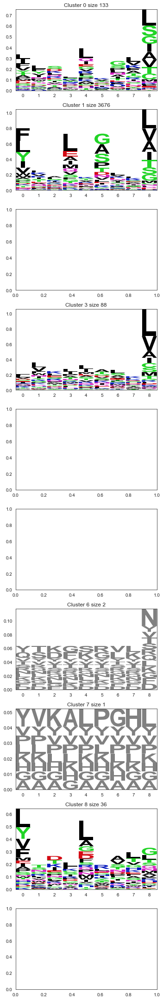

In [731]:
pd.DataFrame(filtered.groupby(['label', 'core_len'],
                              as_index=False).size())  #.pivot(index='size', columns=['label', 'core_len'])
import logomaker
import matplotlib.pyplot as plt

unique_labels = np.unique(clustering.labels_)
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3 * len(unique_labels)))
for label in unique_labels:
    filtered_for_label = filtered[filtered['label'] == label]
    if len(filtered_for_label) > 0 :
        peptides = filtered_for_label['core_peptide'].values

        matrix = logomaker.alignment_to_matrix(peptides)

        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        ww_logo = logomaker.Logo(info_matrix,
                                 # font_name='Arial Rounded MT Bold',
                                 ax=axes[label]
                                 )
        ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()

In [732]:
filtered['core_path'].astype(str).unique()

array(['[3.6 0.  0.  3.6 0.  3.6 0.  0.  3.6]',
       '[3.82 0.   0.   3.82 0.   3.82 0.   0.   3.05]',
       '[3.67 0.   0.   3.67 0.   3.67 0.   0.   3.67]', ...,
       '[3.7  0.   0.   3.7  0.   3.7  0.   0.   0.74]',
       '[3.87 0.   0.   3.87 0.   3.87 0.   0.   3.14]',
       '[2.92 0.   0.   3.67 0.   3.67 0.   0.   3.67]'], dtype=object)

In [733]:
core_length = 9
for i in range(core_length):
    filtered[i] = filtered['core_path'].map(lambda x :x[i])

In [734]:

values_to_run_clustering_on = filtered[[i for i in range(core_length)]] #+ ['norm_vi_prob']
values_to_run_clustering_on = StandardScaler().fit_transform(values_to_run_clustering_on)

pca = get_pca(values_to_run_clustering_on)

Shape (3936, 9)
Explained variation per principal component: [0.51742788 0.2012217 ]


In [735]:
pca_result = pca.transform(values_to_run_clustering_on)
filtered[['pca0', 'pca1']] = pca_result


In [736]:
from sklearn.cluster import KMeans

clustering = KMeans(n_clusters=10).fit(values_to_run_clustering_on)
clustering.labels_

array([5, 5, 5, ..., 5, 9, 5])

<AxesSubplot:xlabel='pca0', ylabel='pca1'>

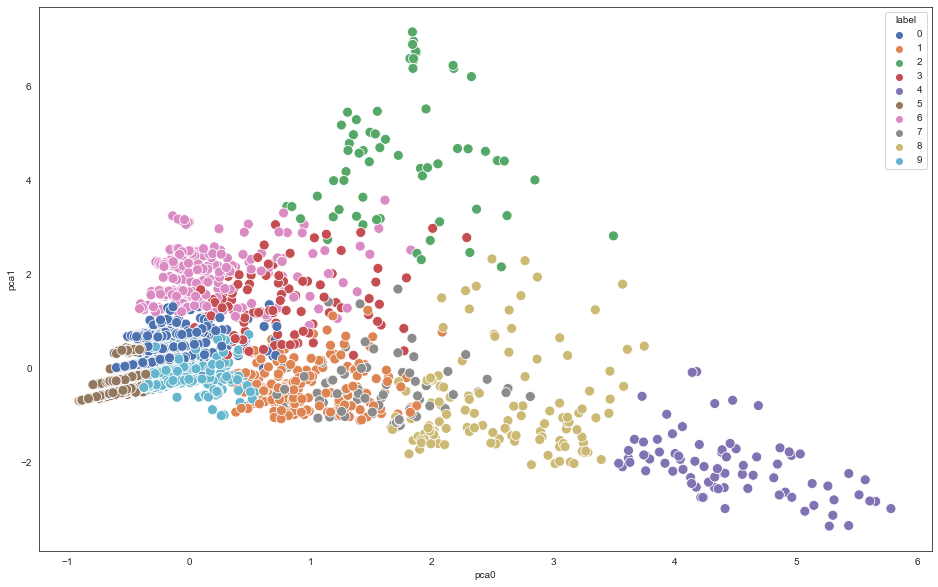

In [739]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_style("white")
fig, ax = plt.subplots(figsize=(16, 10))
filtered['label'] = clustering.labels_
sns.scatterplot(data=filtered, x='pca0', y='pca1', hue='label', s=100,palette='deep', ax=ax)

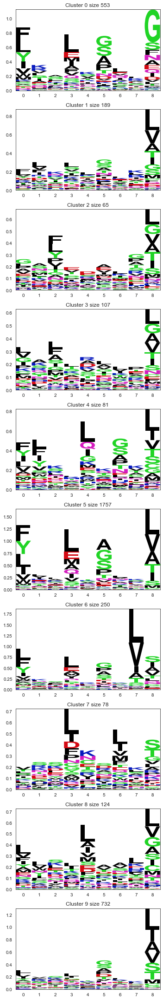

In [740]:
import logomaker
import matplotlib.pyplot as plt
unique_labels = np.unique(clustering.labels_)
fig, axes = plt.subplots(nrows=len(unique_labels), ncols=1, figsize=(5, 3*len(unique_labels)))
for label in unique_labels:
    filtered_for_label = filtered[filtered['label'] == label]

    matrix = logomaker.alignment_to_matrix(filtered_for_label['core_peptide'].values)

    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    ww_logo = logomaker.Logo(info_matrix,
                             # font_name='Arial Rounded MT Bold',
                             ax=axes[label]
                             )
    ww_logo.ax.set_title(f"Cluster {label} size {len(filtered_for_label)}")
plt.tight_layout()

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
LPWNSLPAKTLSK,"[1.97, 1.97, 3.94, 3.94, 3.94, 4.93, 4.93, 3.9...",0,11,12,13,LPWNSLPAKTLS,"[1.97, 1.97, 3.94, 3.94, 3.94, 4.93, 4.93, 3.9..."
IDPIWSLAANHLS,"[0.0, 2.87, 2.87, 3.86, 3.86, 3.86, 4.85, 4.85...",1,12,12,13,DPIWSLAANHLS,"[2.87, 2.87, 3.86, 3.86, 3.86, 4.85, 4.85, 1.9..."
DSRLVLEVAQHLG,"[0.99, 2.94, 2.94, 3.94, 3.94, 3.94, 4.92, 3.9...",0,12,13,13,DSRLVLEVAQHLG,"[0.99, 2.94, 2.94, 3.94, 3.94, 3.94, 4.92, 3.9..."
FLSFPTTKTYFPH,"[1.91, 4.81, 4.81, 4.81, 4.81, 4.81, 4.81, 2.9...",0,8,9,13,FLSFPTTKT,"[1.91, 4.81, 4.81, 4.81, 4.81, 4.81, 4.81, 2.9..."
AAGYDVEKNNSRI,"[0.97, 2.91, 2.91, 3.9, 3.9, 3.9, 4.86, 3.89, ...",0,12,13,13,AAGYDVEKNNSRI,"[0.97, 2.91, 2.91, 3.9, 3.9, 3.9, 4.86, 3.89, ..."
...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,"[0.0, 0.99, 2.95, 2.95, 3.91, 3.91, 3.91, 4.89...",1,13,13,18,AAVYTLAKTPLIA,"[0.99, 2.95, 2.95, 3.91, 3.91, 3.91, 4.89, 3.9..."
AVPGKTFVSITPAEVGVL,"[0.0, 0.0, 0.0, 1.0, 2.99, 2.99, 3.99, 3.99, 3...",3,15,13,18,GKTFVSITPAEVG,"[1.0, 2.99, 2.99, 3.99, 3.99, 3.99, 4.98, 3.98..."
VPHLRYLRLDGNYLKPPI,"[0.0, 1.95, 2.92, 2.92, 2.92, 3.92, 3.92, 3.92...",1,14,14,18,PHLRYLRLDGNYLK,"[1.95, 2.92, 2.92, 2.92, 3.92, 3.92, 3.92, 4.9..."
DIRRFDPIPAQYVRVYPE,"[0.0, 0.99, 2.95, 2.95, 3.94, 3.94, 3.94, 4.93...",1,13,13,18,IRRFDPIPAQYVR,"[0.99, 2.95, 2.95, 3.94, 3.94, 3.94, 4.93, 3.9..."


In [288]:
total_df.core_len.value_counts()

13    5212
12    2337
14    1201
11    1174
10    1102
15     289
9      181
16     107
8       36
17      27
18      10
Name: core_len, dtype: int64

In [130]:
df = total_df
target_core_len = 15
df = df[df['core_len'] == target_core_len]

In [131]:
total_df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path
RSTYNHLSSWLTD,"[0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,12,12,13,STYNHLSSWLTD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
KMYFALIDTKAYK,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,KMYFALIDTKAY,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
PGLARQAPKPRKQ,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,PGLARQAPKPRK,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
AEILELAGNAARD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,AEILELAGNAAR,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
SYVSLKAPLTKPL,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0,11,12,13,SYVSLKAPLTKP,"[1.02, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
...,...,...,...,...,...,...,...
GLAKAKPEASFQVWNKDS,"[0.0, 0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,13,12,18,AKAKPEASFQVW,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
LPLTVTSQQGVKVKFPPN,"[0.0, 1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,13,13,18,PLTVTSQQGVKVK,"[1.01, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
GPKPVVFLQHGLLADSSN,"[0.0, 1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",1,14,14,18,PKPVVFLQHGLLAD,"[1.03, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
TGGKYIGERSVRVWGHRF,"[0.0, 0.0, 1.04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",2,13,12,18,GKYIGERSVRVW,"[1.04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."


In [132]:
peptides = df.index.values
core_starts = df['core_start'].values
core_ends = df['core_end'].values


In [133]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

In [51]:
make_logo_for_data(peptides, "test")

LogomakerError: all elements of sequences must have the same length.

In [134]:
df = total_df
target_core_len = 15
df = df[df['core_len'] == target_core_len]
cores = [peptide[core_starts[i]:core_ends[i]+1] for i,peptide in enumerate(peptides)]


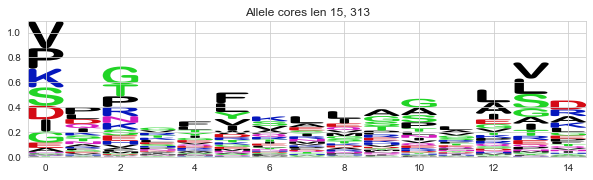

In [135]:
make_logo_for_data(cores, f"cores len {target_core_len}")

In [128]:
df.core_start.value_counts()

0    742
1    537
2     70
3     28
4      5
Name: core_start, dtype: int64

In [129]:
df.peptide_len.value_counts()

15    705
16    272
17    209
18    141
14     55
Name: peptide_len, dtype: int64

In [248]:
df

,simplified_path,core_start,core_end,core_len,peptide_len,core_peptide,core_path,Gibbs_core
MDNDLAATNDHNVME,"[0.0, 0.97, 2.92, 2.92, 3.86, 3.86, 3.86, 4.8,...",2,10,9,15,NDLAATNDH,"[2.92, 2.92, 3.86, 3.86, 3.86, 4.8, 3.83, 1.88...",NaN
EFHLDGEVLSLDKLK,"[0.0, 2.85, 2.85, 3.84, 4.81, 4.81, 4.81, 4.81...",1,9,9,15,FHLDGEVLS,"[2.85, 2.85, 3.84, 4.81, 4.81, 4.81, 4.81, 2.9...",NaN
SPSIVIALAGNKADL,"[0.95, 0.95, 2.93, 2.93, 3.92, 3.92, 3.92, 3.9...",2,10,9,15,SIVIALAGN,"[2.93, 2.93, 3.92, 3.92, 3.92, 3.97, 3.97, 1.9...",VIALAGNKA
ERSLWIIFSKNLNIK,"[0.99, 2.92, 2.92, 3.9, 3.9, 3.9, 4.87, 3.88, ...",1,9,9,15,RSLWIIFSK,"[2.92, 2.92, 3.9, 3.9, 3.9, 4.87, 3.88, 1.95, ...",LWIIFSKNL
LSYRSLQPETFAVVD,"[1.97, 1.97, 3.96, 3.96, 3.96, 4.9, 4.9, 3.92,...",0,8,9,15,LSYRSLQPE,"[1.97, 1.97, 3.96, 3.96, 3.96, 4.9, 4.9, 3.92,...",YRSLQPETF
...,...,...,...,...,...,...,...,...
SKFMQEINIEEQEYQ,"[0.94, 1.9, 2.89, 4.82, 4.82, 4.82, 4.82, 4.82...",1,9,9,15,KFMQEINIE,"[1.9, 2.89, 4.82, 4.82, 4.82, 4.82, 4.82, 3.88...",FMQEINIEE
APVGIMFLVAGKIVE,"[0.0, 0.0, 2.88, 2.88, 3.86, 3.86, 3.86, 4.85,...",2,10,9,15,VGIMFLVAG,"[2.88, 2.88, 3.86, 3.86, 3.86, 4.85, 4.85, 2.9...",IMFLVAGKI
AGLIAIVMVTILLCC,"[1.9, 2.82, 3.77, 3.77, 3.77, 3.77, 3.77, 3.81...",0,8,9,15,AGLIAIVMV,"[1.9, 2.82, 3.77, 3.77, 3.77, 3.77, 3.77, 3.81...",NaN
LLIIFKNQASRPYNI,"[0.0, 0.99, 2.96, 2.96, 4.85, 4.85, 4.85, 4.85...",2,10,9,15,IIFKNQASR,"[2.96, 2.96, 4.85, 4.85, 4.85, 4.85, 3.86, 1.8...",FKNQASRPY


# Continue with old approach

# Calculate viterbi path for each input peptide

In [99]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


# Check new model in a similar way!

In [100]:
core_start_state= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
core_end_state = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']

In [101]:
from tqdm import tqdm
def get_all_viterbi_paths_for_model_and_sequences_mark_core(model, peptides, edge_value="log_probability", precision=4,
                                                           start_states=None,
                                                            end_states=None):
    print(f"Model {model.name}")
    model_graph = model.graph
    print(f"Core starts at {start_states} and ends at {end_states}")
    print("Get viterbi paths for each peptide...")
    
    
    

    result_probs = list()
    result_normalized_probs = list()
    result_lens = list()
    result_paths = list()
    result_peptides = list()
    result_viterbi_probs = list()
    result_start_core = list()
    result_end_core = list()


    for i, peptide in tqdm(enumerate(peptides), total=len(peptides)):
        viterbi_prob, path = model.viterbi(peptide)
        # calulate onlu edges prob
        prob_for_path = 0 if edge_value == "log_probability" else 1
        path_nodes = [path_tuple[1] for path_tuple in path]

        path_length = len(path_nodes)
        result_paths.append(">".join([node.name for node in path_nodes]))
        
        start_state_indexes =  [i - 1  for i, state in enumerate(path_nodes) if state.name in start_states] #minus 1 because of start_state
        end_state_indexes =  [i - 1 for i, state in enumerate(path_nodes) if state.name in end_states] #minus 1 because of start_state

        start_core = start_state_indexes[0] if len(start_state_indexes) > 0 else np.nan
        end_core = end_state_indexes[-1] if len(end_state_indexes) > 0 else np.nan

        node_from = path_nodes.pop(0)
        while path_nodes:
            node_to = path_nodes.pop(0)
            data = model_graph.get_edge_data(node_from, node_to, default=None)
            log_probability = data['probability']
            # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
            if edge_value == "log_probability":
                prob_for_path = prob_for_path + log_probability
            else:
                prob_for_path = prob_for_path * np.exp(log_probability)
            # print(f"edge {edge}")
            node_from = node_to
        result_lens.append(path_length - 2)
        result_probs.append(prob_for_path)
        result_normalized_probs.append(prob_for_path / path_length)
        result_viterbi_probs.append(viterbi_prob)
        result_start_core.append(start_core)
        result_end_core.append(end_core)
    # unique_paths = list(path_code_to_path.values())
    # for path in tqdm(unique_paths):
    #     prob_for_path = 0 if edge_value == "log_probability" else 1
    #     path_edges = path.copy()
    #     node_from = path_edges.pop(0)
    #     while path_edges:
    #         node_to = path_edges.pop(0)
    #         data = model_graph.get_edge_data(node_from, node_to, default=None)
    #         log_probability = data['probability']
    #         # print(node_from, node_to,  np.exp(edge['label']), "total_prob", prob_for_path)
    #         if edge_value == "log_probability":
    #             prob_for_path = prob_for_path + log_probability
    #         else:
    #             prob_for_path = prob_for_path * np.exp(log_probability)
    #         # print(f"edge {edge}")
    #         node_from = node_to
    #     result_paths.append(">".join([node.name for node in path]))
    #     result_lens.append(len(path) - 2)
    #     result_probs.append(prob_for_path)
    #     # normalize
    #     result_normalized_probs.append(prob_for_path / len(path))

    paths_df = pd.DataFrame(
        {"path": result_paths, "prob": result_probs, "normalized_prob": result_normalized_probs, "core_start": result_start_core, "core_end": result_end_core, "len": result_lens,
         "viterbi_probs": result_viterbi_probs}, index=peptides)
    # paths_df = paths_df.sort_values('normalized_prob', ascending=False)
    # paths_df = paths_df.reset_index(drop=True)
    return paths_df


In [102]:
per_model_anchors = dict()
per_name_models = per_name_binding_model
core_start_state= MODELS_DESCRIPTIONS[selected_models[0]]['core_start_state']
core_end_state = MODELS_DESCRIPTIONS[selected_models[0]]['core_end_state']
for model_key, model in per_name_models.items():
    per_model_anchors[model_key] = dict()
    per_model_anchors[model_key]['max'] = model.states[core_end_state].name
    per_model_anchors[model_key]['min'] = model.states[core_start_state].name
    

In [103]:
per_model_anchors

{'0_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '1_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '2_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '3_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'},
 '4_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0': {'max': 's026',
  'min': 's025'}}

In [104]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [105]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    viterbi_paths = get_all_viterbi_paths_for_model_and_sequences_mark_core(model, allele_peptides,
                                                                                   start_states=per_model_anchors[model_key]['min'],
                                                                                   end_states=per_model_anchors[model_key]['max'])
    result_df[f'core_start_{i}'] = viterbi_paths['core_start'].values
    result_df[f'core_end_{i}'] = viterbi_paths['core_end'].values
    result_df[f'v_prob_{i}'] = viterbi_paths['viterbi_probs'].values
    
    
    #find anchor for each model
    

Model 0_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:01<00:00, 11463.65it/s]


Model 1_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:01<00:00, 10521.43it/s]


Model 2_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 13474.82it/s]


Model 3_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 12001.01it/s]


Model 4_run-13-14-15-16-17-18-25-st-viterbi-alg-30-min_iters_model-HLA_DRB1_01_01-0
Core starts at s025 and ends at s026
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 16341.91it/s]


In [106]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4
LPWNSLPAKTLSK,5,11,-36.433899,0,7,-38.300557,2,8,-42.064700,2,8,-35.705307,0,6,-39.349545
IDPIWSLAANHLS,6,12,-38.122537,1,7,-38.486473,1,7,-39.396837,3,9,-37.676468,1,7,-39.453690
DSRLVLEVAQHLG,6,12,-38.290449,1,7,-37.092241,0,6,-37.086968,3,9,-36.277509,1,8,-36.589126
FLSFPTTKTYFPH,1,7,-42.770012,1,8,-44.869600,0,6,-44.325921,0,6,-45.850577,1,8,-44.765592
AAGYDVEKNNSRI,6,12,-42.594572,1,8,-37.728252,0,6,-40.328688,3,9,-37.386060,1,9,-41.017244
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,7,13,-54.773572,2,9,-52.140510,1,7,-52.915872,4,11,-53.748754,2,9,-53.080843
AVPGKTFVSITPAEVGVL,9,15,-52.998724,4,10,-50.204575,3,9,-50.163255,6,12,-50.067367,4,10,-50.569509
VPHLRYLRLDGNYLKPPI,8,14,-52.461933,1,8,-54.117145,2,8,-53.838727,5,11,-52.352251,1,8,-53.511097
DIRRFDPIPAQYVRVYPE,7,13,-55.379731,2,9,-56.036721,1,7,-55.581909,4,10,-55.175012,2,8,-56.240885


In [343]:
result_df['len'] = result_df.index.str.len()

In [344]:
result_df[result_df['len']==15]

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
IVLSSELRLSHSRTH,2,8,-46.184237,4,11,-47.084595,3,9,-46.249582,6,12,-46.518778,5,13,-48.112668,15
MDNDLAATNDHNVME,7,13,-51.834905,2,8,-50.808451,1,7,-51.214223,4,10,-51.765642,2,8,-52.039667,15
EFHLDGEVLSLDKLK,3,9,-42.866300,1,7,-46.328549,4,10,-44.727821,1,7,-46.650210,1,8,-45.757055,15
SPSIVIALAGNKADL,7,13,-40.504891,2,8,-41.875212,0,6,-42.439952,4,10,-40.557440,2,8,-40.184039,15
ERSLWIIFSKNLNIK,6,12,-46.847361,1,7,-47.213453,0,6,-47.347887,3,9,-47.063905,1,7,-47.880625,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,4,10,-49.378744,2,8,-47.076590,1,7,-47.573108,4,10,-46.711595,2,8,-47.620495,15
ETQYSEMFGMVLAPA,6,12,-46.075367,1,7,-45.956662,0,6,-45.715244,3,9,-44.801549,1,7,-45.906706,15
FNMVYMPASWVMRIM,5,11,-52.155026,2,8,-53.815348,1,7,-53.146985,2,8,-52.295265,2,11,-53.376243,15
IFLSKDLQADIKGRD,7,13,-45.654156,2,8,-48.842987,3,9,-48.437682,3,9,-48.424849,4,10,-47.178443,15


In [345]:
peptide = 'IVLSSELRLSHSRTH'

model = per_name_models[list(per_name_models.keys())[0]]

In [346]:
prob, path = model.viterbi(peptide)

In [347]:
[item[0] for item in path]

[29, 27, 27, 25, 3, 6, 12, 16, 24, 26, 28, 28, 28, 28, 28, 28, 30]

In [348]:
peptide

'IVLSSELRLSHSRTH'

In [349]:
prob, path = model.maximum_a_posteriori([i for i in peptide])


In [350]:
[item[0] for item in path]

[27, 27, 27, 3, 6, 12, 16, 24, 26, 28, 28, 28, 28, 28, 28]

In [351]:
result_df

,core_start_0,core_end_0,v_prob_0,core_start_1,core_end_1,v_prob_1,core_start_2,core_end_2,v_prob_2,core_start_3,core_end_3,v_prob_3,core_start_4,core_end_4,v_prob_4,len
LPWNSLPAKTLSK,5,11,-36.433899,0,7,-38.300557,2,8,-42.064700,2,8,-35.705307,0,6,-39.349545,13
IDPIWSLAANHLS,6,12,-38.122537,1,7,-38.486473,1,7,-39.396837,3,9,-37.676468,1,7,-39.453690,13
DSRLVLEVAQHLG,6,12,-38.290449,1,7,-37.092241,0,6,-37.086968,3,9,-36.277509,1,8,-36.589126,13
FLSFPTTKTYFPH,1,7,-42.770012,1,8,-44.869600,0,6,-44.325921,0,6,-45.850577,1,8,-44.765592,13
AAGYDVEKNNSRI,6,12,-42.594572,1,8,-37.728252,0,6,-40.328688,3,9,-37.386060,1,9,-41.017244,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
EAAVYTLAKTPLIADVYY,7,13,-54.773572,2,9,-52.140510,1,7,-52.915872,4,11,-53.748754,2,9,-53.080843,18
AVPGKTFVSITPAEVGVL,9,15,-52.998724,4,10,-50.204575,3,9,-50.163255,6,12,-50.067367,4,10,-50.569509,18
VPHLRYLRLDGNYLKPPI,8,14,-52.461933,1,8,-54.117145,2,8,-53.838727,5,11,-52.352251,1,8,-53.511097,18
DIRRFDPIPAQYVRVYPE,7,13,-55.379731,2,9,-56.036721,1,7,-55.581909,4,10,-55.175012,2,8,-56.240885,18


In [352]:
result_df['core_length'] = result_df['core_end_1'] + 1- result_df['core_start_1']

In [353]:
result_df['core_length'].value_counts()

7     7711
8     3687
9      587
10      16
Name: core_length, dtype: int64

In [354]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

7     4606
8     1966
9      302
10      12
Name: core_length, dtype: int64

In [362]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 8]

NameError: name 'result_df' is not defined

In [370]:
peptides = df.index.values 
core_starts = df['core_start_1'].values
core_ends = df['core_end_1'].values


In [371]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

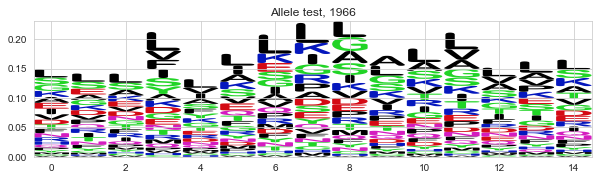

In [372]:
make_logo_for_data(peptides, "test")

In [373]:
cores = [peptide[core_starts[i]:core_ends[i] + 1] for i,peptide in enumerate(peptides)]
         

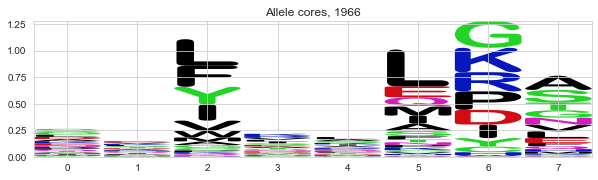

In [374]:
make_logo_for_data(cores, "cores")

In [368]:
df['core_start_0'].value_counts()

6    1113
7    1098
5     659
4     476
8     454
3     426
2     226
1     154
Name: core_start_0, dtype: int64

## Forward-Backward estimate to find core

In [325]:
per_model_core_start = defaultdict(list)
per_model_core_end = defaultdict(list)

result_df = pd.DataFrame(index=allele_peptides)

for i, (model_key, model) in enumerate(per_name_models.items()):
    core_starts = list()
    core_ends = list()
    for peptide in allele_peptides:
        fb_result = model.forward_backward(peptide)[1]
        arg_min = fb_result.argmax(axis=0)
        min_position = arg_min[core_start_state]
        max_position = arg_min[core_end_state]
        # assert min_position < max_position
        core_starts.append(min_position)
        core_ends.append(max_position)
    
    result_df[f'core_start_{i}'] = core_starts
    result_df[f'core_end_{i}'] = core_ends


In [336]:
result_df['len'] = result_df.index.str.len()
result_df['core_length'] = result_df['core_end_1'] + 1 - result_df['core_start_1']

In [327]:
result_df['core_length'].value_counts()

7     11729
8       201
9        11
11       10
6         9
4         9
10        8
5         7
12        5
3         4
2         4
13        3
0         1
Name: core_length, dtype: int64

In [328]:
result_df[result_df['len'] == 15]['core_length'].value_counts()

7     6732
8      107
9        9
4        8
11       8
10       6
12       4
6        4
5        4
3        2
2        2
Name: core_length, dtype: int64

In [329]:
result_df[result_df['len'] == 15]

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
IVLSSELRLSHSRTH,2,8,4,11,3,9,6,12,5,13,15,7
MDNDLAATNDHNVME,7,13,2,8,1,7,4,10,2,8,15,7
EFHLDGEVLSLDKLK,3,9,1,7,4,10,1,7,1,8,15,7
SPSIVIALAGNKADL,7,13,2,8,0,7,4,10,2,8,15,7
ERSLWIIFSKNLNIK,6,12,1,7,0,6,3,9,1,7,15,7
...,...,...,...,...,...,...,...,...,...,...,...,...
LLIIFKNQASRPYNI,4,10,2,8,1,7,4,10,2,8,15,7
ETQYSEMFGMVLAPA,6,12,1,7,0,6,3,9,1,7,15,7
FNMVYMPASWVMRIM,5,11,2,8,1,7,2,8,2,11,15,7
IFLSKDLQADIKGRD,7,13,2,8,3,9,3,9,4,10,15,7


In [330]:
df = result_df[result_df['len'] == 15]
df = df[df['core_length'] == 7]

In [331]:
peptides = df.index.values 
core_starts = df['core_start_0'].values
core_ends = df['core_end_0'].values


In [332]:
def make_logo_for_data(binders_array, name):
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
    ww_logo.ax.set_title(f"Allele {name}, {len(binders_array)}")

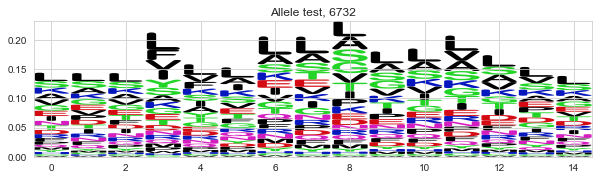

In [333]:
make_logo_for_data(peptides, "test")

In [334]:
cores = [peptide[core_starts[i]+1:core_ends[i]] for i,peptide in enumerate(peptides)]
         

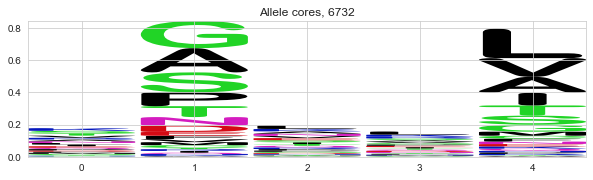

In [335]:
make_logo_for_data(cores, "cores")

In [100]:
df

,core_start_0,core_end_0,core_start_1,core_end_1,core_start_2,core_end_2,core_start_3,core_end_3,core_start_4,core_end_4,len,core_length
IVLSSELRLSHSRTH,1,13,1,13,1,13,1,13,1,13,15,13
MDNDLAATNDHNVME,1,13,1,13,1,13,1,13,1,13,15,13
SPSIVIALAGNKADL,1,13,1,13,1,13,1,13,1,13,15,13
ERSLWIIFSKNLNIK,1,13,1,12,1,12,1,12,1,12,15,13
LSYRSLQPETFAVVD,1,13,1,12,1,12,1,12,0,13,15,13
...,...,...,...,...,...,...,...,...,...,...,...,...
FDTGLMNDTGPILRL,1,13,1,13,1,13,1,13,1,13,15,13
IMNRWTLQMGFPVIT,1,13,1,13,1,13,1,13,1,13,15,13
APVGIMFLVAGKIVE,1,13,1,13,1,13,1,13,1,13,15,13
AGLIAIVMVTILLCC,1,13,1,13,1,13,1,13,1,13,15,13


## Calculate viterbi paths for train data (Try to find anchors)

In [101]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])


In [102]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences
allele_bw_paths_df = get_all_viterbi_paths_for_model_and_sequences(model, allele_peptides)


Model 4_run-13-14-15-16-17-18-25-st-baum-welch-alg-30-min_iters_model-HLA_DRB1_01_01-0
Get viterbi paths for each peptide...


100%|██████████| 12001/12001 [00:00<00:00, 19774.64it/s]


Select unique paths...
	Unique paths: 2225


100%|██████████| 2225/2225 [00:00<00:00, 37955.57it/s]


In [103]:
allele_bw_paths_df

,path,prob,normalized_prob,len,mean_viterbi,peptide_cnts
0,grouped_model-start>s027>s025>s000>s006>s007>s...,-6.338333,-0.396146,14,-41.321140,160
1,grouped_model-start>s027>s025>s001>s000>s006>s...,-6.821602,-0.401271,15,-48.740790,174
2,grouped_model-start>s027>s025>s001>s004>s000>s...,-7.267903,-0.403772,16,-47.953576,41
3,grouped_model-start>s027>s025>s004>s000>s006>s...,-6.921293,-0.407135,15,-47.900938,144
4,grouped_model-start>s027>s025>s000>s006>s007>s...,-6.547243,-0.409203,14,-40.803551,98
...,...,...,...,...,...,...
2220,grouped_model-start>s025>s002>s009>s014>s015>s...,-17.089083,-1.005240,15,-55.188543,1
2221,grouped_model-start>s027>s025>s001>s004>s000>s...,-15.316085,-1.021072,13,-45.592282,1
2222,grouped_model-start>s025>s000>s005>s012>s016>s...,-15.373904,-1.024927,13,-47.112920,1
2223,grouped_model-start>s027>s027>s025>s001>s004>s...,-17.423946,-1.024938,15,-59.044016,1


In [104]:
state_names = [f"s{i:03d}".format(i) for i in range(len(model.states) - 2)] # minus start minus end

# allele_bw_paths_df.loc[:,state_names] = 0

per_state_counts = dict()

In [105]:
for state_name in state_names:
    per_state_counts[state_name] =  allele_bw_paths_df[allele_bw_paths_df['path'].str.contains(state_name)]['peptide_cnts'].sum()


In [106]:
per_state_counts

{'s000': 7849,
 's001': 4522,
 's002': 2685,
 's003': 1545,
 's004': 3529,
 's005': 109,
 's006': 10080,
 's007': 10212,
 's008': 586,
 's009': 1766,
 's010': 3671,
 's011': 8268,
 's012': 187,
 's013': 11703,
 's014': 313,
 's015': 11508,
 's016': 11389,
 's017': 342,
 's018': 30,
 's019': 4817,
 's020': 1161,
 's021': 8849,
 's022': 7537,
 's023': 306,
 's024': 9942,
 's025': 12001,
 's026': 12001,
 's027': 10239,
 's028': 11996}

In [107]:
import seaborn as sns

In [108]:
df = pd.DataFrame.from_dict(per_state_counts, orient='index', columns=['cnt'])

# sns.barplot(x=list(per_state_counts.keys()), y=list(per_state_counts.values()))

<AxesSubplot:>

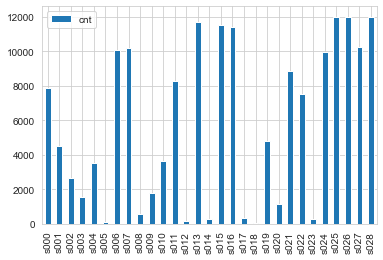

In [109]:
df.plot(kind='bar')

In [110]:
df.sort_values(by='cnt', ascending=False)

,cnt
s026,12001
s025,12001
s028,11996
s013,11703
s015,11508
s016,11389
s027,10239
s007,10212
s006,10080
s024,9942


In [88]:
model.dense_transition_matrix()

array([[0.        , 0.18783749, 0.24838837, ..., 0.        , 0.        ,
        0.        ],
       [0.02338106, 0.        , 0.08356533, ..., 0.        , 0.        ,
        0.        ],
       [0.10202855, 0.22541672, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.70792018],
       [0.24782062, 0.12390521, 0.03135931, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])